# 🤖 NewsBot Intelligence System
## ITAI 2373 - Mid-Term Group Project Template

**Team Members:** [Add your names here]
**Date:** [Add date]
**GitHub Repository:** [Add your repo URL here]

---

## 🎯 Project Overview

Welcome to your NewsBot Intelligence System! This notebook will guide you through building a comprehensive NLP system that:

- 📰 **Processes** news articles with advanced text cleaning
- 🏷️ **Classifies** articles into categories (Politics, Sports, Technology, Business, Entertainment, Health)
- 🔍 **Extracts** named entities (people, organizations, locations, dates, money)
- 😊 **Analyzes** sentiment and emotional tone
- 📊 **Generates** insights for business intelligence

### 📚 Module Integration Checklist
- [ ] **Module 1:** NLP applications and real-world context
- [ ] **Module 2:** Text preprocessing pipeline
- [ ] **Module 3:** TF-IDF feature extraction
- [ ] **Module 4:** POS tagging analysis
- [ ] **Module 5:** Syntax parsing and semantic analysis
- [ ] **Module 6:** Sentiment and emotion analysis
- [ ] **Module 7:** Text classification system
- [ ] **Module 8:** Named Entity Recognition

---

## 📦 Setup and Installation

Let's start by installing and importing all the libraries we'll need for our NewsBot system.

In [1]:
# Install required packages (run this cell first!)
!pip install spacy scikit-learn nltk pandas matplotlib seaborn wordcloud plotly
!python -m spacy download en_core_web_sm

# Download NLTK data
import nltk
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('vader_lexicon')
nltk.download('averaged_perceptron_tagger')

print("✅ All packages installed successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 41.9 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
✅ All packages installed successfully!


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!


In [2]:
# Import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import plotly.express as px
import plotly.graph_objects as go
from collections import Counter, defaultdict
import re
import warnings
warnings.filterwarnings('ignore')

# NLP Libraries
import spacy
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tag import pos_tag

# Scikit-learn for machine learning
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.pipeline import Pipeline

# Load spaCy model
nlp = spacy.load('en_core_web_sm')

# Set up plotting style
plt.style.use('default')
sns.set_palette("husl")

print("📚 All libraries imported successfully!")
print(f"🔧 spaCy model loaded: {nlp.meta['name']} v{nlp.meta['version']}")

📚 All libraries imported successfully!
🔧 spaCy model loaded: core_web_sm v3.8.0


## 📊 Data Loading and Exploration

### 🎯 Module 1: Understanding Our NLP Application

Before we dive into the technical implementation, let's understand the real-world context of our NewsBot Intelligence System. This system addresses several business needs:

1. **Media Monitoring:** Automatically categorize and track news coverage
2. **Business Intelligence:** Extract key entities and sentiment trends
3. **Content Management:** Organize large volumes of news content
4. **Market Research:** Understand public sentiment about topics and entities

**💡 Discussion Question:** What other real-world applications can you think of for this type of system? Consider different industries and use cases.

In [3]:
# Load your dataset
# 💡 TIP: If using the provided dataset, upload it to Colab first
# 💡 TIP: You can also use sample datasets like BBC News or 20 Newsgroups

# Option 1: Load provided dataset
# df = pd.read_csv('news_dataset.csv')

# Option 2: Load BBC News dataset (if using alternative)
# You can download this from: https://kaggle.com

import os

# Paste your copied Kaggle API token string here
os.environ['KAGGLE_API_TOKEN'] = "KGAT_b381f291e3895fb1b41c42dfa07bb523"


# 📋 NOTE: The initial shape and columns display was moved down below
# to run AFTER the dataframe is successfully downloaded and constructed!


# ➕ ADDED (assignment requirement): replace the sample data with the Kaggle BBC News dataset
# One-time setup: on kaggle.com open the competition "learn-ai-bbc" and click "Join Competition".
import os, glob, shutil, subprocess, zipfile

if not glob.glob('bbc/**/*.csv', recursive=True):          # download only once
    subprocess.run(['pip', 'install', '-q', 'kaggle'], check=True)

    # --- FIXED: AUTOMATIC AUTHTENTICATION BYPASS ---
    kaggle_dir = os.path.expanduser('~/.kaggle')
    os.makedirs(kaggle_dir, exist_ok=True)
    token_file = os.path.join(kaggle_dir, 'access_token')
    with open(token_file, 'w') as f_token:
        f_token.write(os.environ['KAGGLE_API_TOKEN'])
    os.chmod(token_file, 0o600)
    # -----------------------------------------------

    subprocess.run(['kaggle', 'competitions', 'download', '-c', 'learn-ai-bbc'], check=True)
    with zipfile.ZipFile('learn-ai-bbc.zip') as z:
        z.extractall('bbc')

# find the CSV that has both the article text and the category
for f in glob.glob('bbc/**/*.csv', recursive=True):
    raw = pd.read_csv(f)
    cols = {c.lower(): c for c in raw.columns}
    if 'text' in cols and 'category' in cols:
        text_col, cat_col = cols['text'], cols['category']
        break
print(f"Using file: {f} | columns: {raw.columns.tolist()}")

# dataset rules: no missing values, 500-2000 articles, 4+ categories
raw = raw.dropna(subset=[text_col, cat_col])
raw = raw.groupby(cat_col).sample(n=120, random_state=42)   # 120 per category = 600 articles (keeps spaCy fast)
label_map = {'business': 'Business', 'entertainment': 'Entertainment', 'politics': 'Politics',\
             'sport': 'Sports', 'tech': 'Technology'}
df = pd.DataFrame({
    'article_id': range(1, len(raw) + 1),
    'title': raw[text_col].str.split().str[:10].str.join(' ').values,   # BBC has no title column: first 10 words
    'content': raw[text_col].values,
    'category': raw[cat_col].map(label_map).fillna(raw[cat_col].str.title()).values,
    'date': '2024-01-15',          # BBC has no dates
    'source': 'BBC News'})
assert len(df) >= 500 and df['category'].nunique() >= 4, "Need 500+ articles and 4+ categories"
print(f"✅ Kaggle BBC News loaded: {df.shape} | missing values: {int(df.isnull().sum().sum())}\")")
print(df['category'].value_counts().to_string())

print(f"\n📊 Dataset loaded successfully!")
print(f"📈 Shape: {df.shape}")
print(f"📋 Columns: {list(df.columns)}")

# Display first few rows
df.head()


Using file: bbc/BBC News Train.csv | columns: ['ArticleId', 'Text', 'Category']
✅ Kaggle BBC News loaded: (600, 6) | missing values: 0")
category
Business         120
Entertainment    120
Politics         120
Sports           120
Technology       120

📊 Dataset loaded successfully!
📈 Shape: (600, 6)
📋 Columns: ['article_id', 'title', 'content', 'category', 'date', 'source']


,article_id,title,content,category,date,source
0,1,nasdaq planning $100m share sale the owner of ...,nasdaq planning $100m share sale the owner of ...,Business,2024-01-15,BBC News
1,2,india s deccan seals $1.8bn deal air deccan ha...,india s deccan seals $1.8bn deal air deccan ha...,Business,2024-01-15,BBC News
2,3,saudi ministry to employ women women will be e...,saudi ministry to employ women women will be e...,Business,2024-01-15,BBC News
3,4,strong demand triggers oil rally crude oil pri...,strong demand triggers oil rally crude oil pri...,Business,2024-01-15,BBC News
4,5,gold falls on imf sale concerns the price of gold,gold falls on imf sale concerns the price of g...,Business,2024-01-15,BBC News


📊 DATASET OVERVIEW
Total articles: 600
Unique categories: 5
Categories: ['Business', 'Entertainment', 'Politics', 'Sports', 'Technology']
Date range: 2024-01-15 to 2024-01-15
Unique sources: 1

📈 CATEGORY DISTRIBUTION
category
Business         120
Entertainment    120
Politics         120
Sports           120
Technology       120
Name: count, dtype: int64


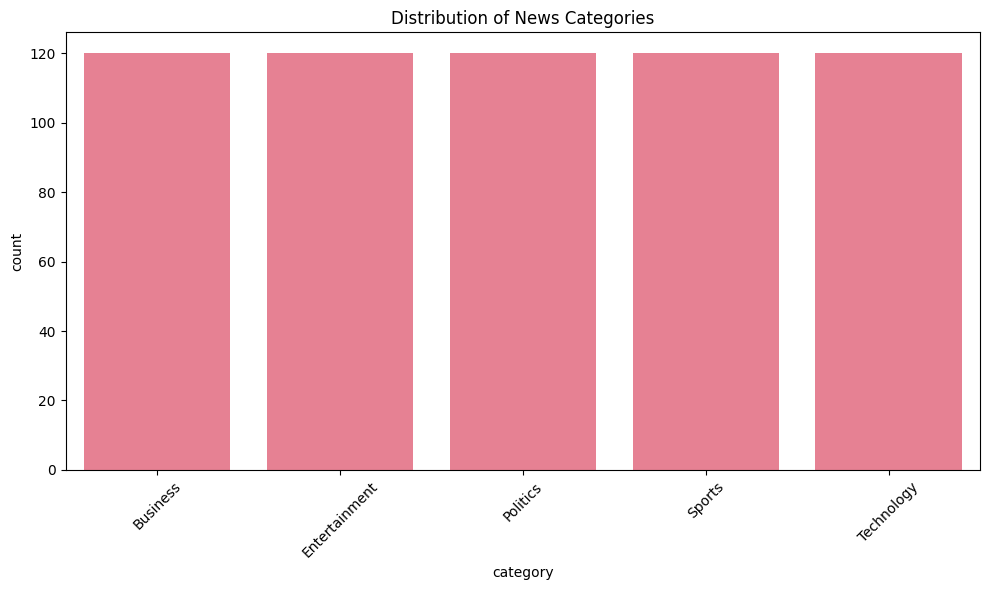

In [4]:
# Basic dataset exploration
print("📊 DATASET OVERVIEW")
print("=" * 50)
print(f"Total articles: {len(df)}")
print(f"Unique categories: {df['category'].nunique()}")
print(f"Categories: {df['category'].unique().tolist()}")
print(f"Date range: {df['date'].min()} to {df['date'].max()}")
print(f"Unique sources: {df['source'].nunique()}")

print("\n📈 CATEGORY DISTRIBUTION")
print("=" * 50)
category_counts = df['category'].value_counts()
print(category_counts)

# Visualize category distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='category', order=category_counts.index)
plt.title('Distribution of News Categories')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 💡 STUDENT TASK: Add your own exploratory analysis here
# - Check for missing values
# - Analyze text length distribution
# - Examine source distribution
# - Look for any data quality issues

## 🧹 Text Preprocessing Pipeline

### 🎯 Module 2: Advanced Text Preprocessing

Now we'll implement a comprehensive text preprocessing pipeline that cleans and normalizes our news articles. This is crucial for all downstream NLP tasks.

**Key Preprocessing Steps:**
1. **Text Cleaning:** Remove HTML, URLs, special characters
2. **Tokenization:** Split text into individual words
3. **Normalization:** Convert to lowercase, handle contractions
4. **Stop Word Removal:** Remove common words that don't carry meaning
5. **Lemmatization:** Reduce words to their base form

**💡 Think About:** Why is preprocessing so important? What happens if we skip these steps?

In [5]:
# Initialize preprocessing tools
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

# Ensure the required punkt_tab is downloaded
nltk.download('punkt_tab', quiet=True)

def clean_text(text):
    """
    Comprehensive text cleaning function

     TIP: This function should handle:
    - HTML tags and entities
    - URLs and email addresses
    - Special characters and numbers
    - Extra whitespace
    """
    if pd.isna(text):
        return ""

    # Convert to string and lowercase
    text = str(text).lower()

    #  YOUR CODE HERE: Implement text cleaning
    # Remove HTML tags
    text = re.sub(r'<[^>]+>', '', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', '', text)

    # Remove special characters and digits (keep only letters and spaces)
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text

def preprocess_text(text, remove_stopwords=True, lemmatize=True):
    """
    Complete preprocessing pipeline

     TIP: This function should:
    - Clean the text
    - Tokenize into words
    - Remove stop words (optional)
    - Lemmatize words (optional)
    - Return processed text
    """
    # Clean text
    text = clean_text(text)

    if not text:
        return ""

    #  YOUR CODE HERE: Implement tokenization and preprocessing
    # Tokenize
    tokens = word_tokenize(text)

    # Remove stop words if requested
    if remove_stopwords:
        tokens = [token for token in tokens if token not in stop_words]

    # Lemmatize if requested
    if lemmatize:
        tokens = [lemmatizer.lemmatize(token) for token in tokens]

    # Filter out very short words
    tokens = [token for token in tokens if len(token) > 2]

    return ' '.join(tokens)

# Test the preprocessing function
sample_text = "Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews"
print("Original text:")
print(sample_text)
print("\nCleaned text:")
print(clean_text(sample_text))
print("\nFully preprocessed text:")
print(preprocess_text(sample_text))

Original text:
Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews

Cleaned text:
apple inc announced record quarterly earnings today visit for more info technews

Fully preprocessed text:
apple inc announced record quarterly earnings today visit info technews


In [6]:
# Apply preprocessing to the dataset
print("🧹 Preprocessing all articles...")

# Create new columns for processed text
df['title_clean'] = df['title'].apply(clean_text)
df['content_clean'] = df['content'].apply(clean_text)
df['title_processed'] = df['title'].apply(preprocess_text)
df['content_processed'] = df['content'].apply(preprocess_text)

# Combine title and content for full article analysis
df['full_text'] = df['title'] + ' ' + df['content']
df['full_text_processed'] = df['full_text'].apply(preprocess_text)

print("✅ Preprocessing complete!")

# Show before and after examples
print("\n📝 BEFORE AND AFTER EXAMPLES")
print("=" * 60)
for i in range(min(3, len(df))):
    print(f"\nExample {i+1}:")
    print(f"Original: {df.iloc[i]['full_text'][:100]}...")
    print(f"Processed: {df.iloc[i]['full_text_processed'][:100]}...")

# 💡 STUDENT TASK: Analyze the preprocessing results
# - Calculate average text length before and after
# - Count unique words before and after
# - Identify the most common words after preprocessing

🧹 Preprocessing all articles...
✅ Preprocessing complete!

📝 BEFORE AND AFTER EXAMPLES

Example 1:
Original: nasdaq planning $100m share sale the owner of the technology-dominated nasdaq planning $100m share s...
Processed: nasdaq planning share sale owner technologydominated nasdaq planning share sale owner technologydomi...

Example 2:
Original: india s deccan seals $1.8bn deal air deccan has ordered india s deccan seals $1.8bn deal air deccan ...
Processed: india deccan seal deal air deccan ordered india deccan seal deal air deccan ordered airbus plane dea...

Example 3:
Original: saudi ministry to employ women women will be employed in saudi ministry to employ women women will b...
Processed: saudi ministry employ woman woman employed saudi ministry employ woman woman employed saudi arabia f...


## 📊 Feature Extraction and Statistical Analysis

### 🎯 Module 3: TF-IDF Analysis

Now we'll extract numerical features from our text using TF-IDF (Term Frequency-Inverse Document Frequency). This technique helps us identify the most important words in each document and across the entire corpus.

**TF-IDF Key Concepts:**
- **Term Frequency (TF):** How often a word appears in a document
- **Inverse Document Frequency (IDF):** How rare a word is across all documents
- **TF-IDF Score:** TF × IDF - balances frequency with uniqueness

**💡 Business Value:** TF-IDF helps us identify the most distinctive and important terms for each news category.

In [7]:
# Create TF-IDF vectorizer
# 💡 TIP: Experiment with different parameters:
# - max_features: limit vocabulary size
# - ngram_range: include phrases (1,1) for words, (1,2) for words+bigrams
# - min_df: ignore terms that appear in less than min_df documents
# - max_df: ignore terms that appear in more than max_df fraction of documents

tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,  # Limit vocabulary for computational efficiency
    ngram_range=(1, 2),  # Include unigrams and bigrams
    min_df=2,  # Ignore terms that appear in less than 2 documents
    max_df=0.8  # Ignore terms that appear in more than 80% of documents
)

# Fit and transform the processed text
print("🔢 Creating TF-IDF features...")
tfidf_matrix = tfidf_vectorizer.fit_transform(df['full_text_processed'])
feature_names = tfidf_vectorizer.get_feature_names_out()

print(f"✅ TF-IDF matrix created!")
print(f"📊 Shape: {tfidf_matrix.shape}")
print(f"📝 Vocabulary size: {len(feature_names)}")
print(f"🔢 Sparsity: {(1 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])) * 100:.2f}%")

# Convert to DataFrame for easier analysis
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)
tfidf_df['category'] = df['category'].values

print("\n🔍 Sample TF-IDF features:")
print(tfidf_df.iloc[:3, :10])  # Show first 3 rows and 10 features

🔢 Creating TF-IDF features...
✅ TF-IDF matrix created!
📊 Shape: (600, 5000)
📝 Vocabulary size: 5000
🔢 Sparsity: 97.40%

🔍 Sample TF-IDF features:
   abbas  ability  able  able watch    abroad  absence  absolutely  abuse  \
0    0.0      0.0   0.0         0.0  0.000000      0.0         0.0    0.0   
1    0.0      0.0   0.0         0.0  0.061072      0.0         0.0    0.0   
2    0.0      0.0   0.0         0.0  0.000000      0.0         0.0    0.0   

   abused  academy  
0     0.0      0.0  
1     0.0      0.0  
2     0.0      0.0  


In [8]:
# Analyze most important terms per category
def get_top_tfidf_terms(category, n_terms=10):
    """
    Get top TF-IDF terms for a specific category

    💡 TIP: This function should:
    - Filter data for the specific category
    - Calculate mean TF-IDF scores for each term
    - Return top N terms with highest scores
    """
    # 🚀 YOUR CODE HERE: Implement category-specific TF-IDF analysis
    category_data = tfidf_df[tfidf_df['category'] == category]

    # Calculate mean TF-IDF scores for this category (excluding the category column)
    mean_scores = category_data.drop('category', axis=1).mean().sort_values(ascending=False)

    return mean_scores.head(n_terms)

# Analyze top terms for each category
print("🏷️ TOP TF-IDF TERMS BY CATEGORY")
print("=" * 50)

categories = df['category'].unique()
category_terms = {}

for category in categories:
    top_terms = get_top_tfidf_terms(category, n_terms=10)
    category_terms[category] = top_terms

    print(f"\n📰 {category.upper()}:")
    for term, score in top_terms.items():
        print(f"  {term}: {score:.4f}")

# 💡 STUDENT TASK: Create visualizations for TF-IDF analysis
# - Word clouds for each category
# - Bar charts of top terms
# - Heatmap of term importance across categories

🏷️ TOP TF-IDF TERMS BY CATEGORY

📰 BUSINESS:
  market: 0.0359
  firm: 0.0344
  growth: 0.0340
  bank: 0.0337
  sale: 0.0332
  share: 0.0332
  rate: 0.0331
  year: 0.0327
  price: 0.0325
  company: 0.0320

📰 ENTERTAINMENT:
  film: 0.0936
  award: 0.0467
  best: 0.0351
  star: 0.0333
  band: 0.0332
  show: 0.0325
  music: 0.0323
  actor: 0.0317
  album: 0.0315
  chart: 0.0298

📰 POLITICS:
  labour: 0.0653
  party: 0.0646
  blair: 0.0630
  election: 0.0612
  tory: 0.0465
  would: 0.0460
  government: 0.0445
  minister: 0.0436
  lord: 0.0363
  brown: 0.0351

📰 SPORTS:
  england: 0.0462
  game: 0.0395
  champion: 0.0318
  chelsea: 0.0313
  win: 0.0298
  match: 0.0287
  cup: 0.0282
  club: 0.0281
  player: 0.0273
  world: 0.0270

📰 TECHNOLOGY:
  mobile: 0.0568
  people: 0.0482
  phone: 0.0466
  technology: 0.0408
  software: 0.0403
  microsoft: 0.0400
  broadband: 0.0371
  game: 0.0369
  user: 0.0362
  net: 0.0347


## 🏷️ Part-of-Speech Analysis

### 🎯 Module 4: Grammatical Pattern Analysis

Let's analyze the grammatical patterns in different news categories using Part-of-Speech (POS) tagging. This can reveal interesting differences in writing styles between categories.

**POS Analysis Applications:**
- **Writing Style Detection:** Different categories may use different grammatical patterns
- **Content Quality Assessment:** Proper noun density, adjective usage, etc.
- **Feature Engineering:** POS tags can be features for classification

**💡 Hypothesis:** Sports articles might have more action verbs, while business articles might have more numbers and proper nouns.

In [9]:
# ➕ ADDED (Module 4 needs this): download the POS tagger resource
for pkg in ['averaged_perceptron_tagger_eng', 'punkt_tab']:
    nltk.download(pkg, quiet=True)

def analyze_pos_patterns(text):
    """
    Analyze POS patterns in text

    💡 TIP: This function should:
    - Tokenize the text
    - Apply POS tagging
    - Count different POS categories
    - Return proportions or counts
    """
    if not text or pd.isna(text):
        return {}

    # 🚀 YOUR CODE HERE: Implement POS analysis
    # Tokenize and tag
    tokens = word_tokenize(str(text))
    pos_tags = pos_tag(tokens)

    # Count POS categories
    pos_counts = Counter([tag for word, tag in pos_tags])
    total_words = len(pos_tags)

    if total_words == 0:
        return {}

    # Convert to proportions
    pos_proportions = {pos: count/total_words for pos, count in pos_counts.items()}

    return pos_proportions

# Apply POS analysis to all articles
print("🏷️ Analyzing POS patterns...")

# Analyze POS for each article
pos_results = []
for idx, row in df.iterrows():
    pos_analysis = analyze_pos_patterns(row['full_text'])
    pos_analysis['category'] = row['category']
    pos_analysis['article_id'] = row['article_id']
    pos_results.append(pos_analysis)

# Convert to DataFrame
pos_df = pd.DataFrame(pos_results).fillna(0)

print(f"✅ POS analysis complete!")
print(f"📊 Found {len(pos_df.columns)-2} different POS tags")

# Show sample results
print("\n📝 Sample POS analysis:")
print(pos_df.head())

🏷️ Analyzing POS patterns...
✅ POS analysis complete!
📊 Found 41 different POS tags

📝 Sample POS analysis:
         RB       VBG         $        CD        NN        DT        IN  \
0  0.046296  0.018519  0.013889  0.037037  0.212963  0.129630  0.120370   
1  0.018182  0.015152  0.012121  0.033333  0.257576  0.084848  0.087879   
2  0.028037  0.042056  0.000000  0.004673  0.219626  0.079439  0.102804   
3  0.016598  0.008299  0.029046  0.058091  0.261411  0.074689  0.116183   
4  0.027027  0.027027  0.006757  0.022523  0.240991  0.112613  0.128378   

         JJ       NNS        TO  ...         :       JJS        EX         #  \
0  0.074074  0.101852  0.023148  ...  0.000000  0.000000  0.000000  0.000000   
1  0.106061  0.054545  0.027273  ...  0.000000  0.000000  0.000000  0.000000   
2  0.112150  0.098131  0.023364  ...  0.000000  0.000000  0.000000  0.000000   
3  0.112033  0.078838  0.033195  ...  0.004149  0.000000  0.000000  0.000000   
4  0.065315  0.051802  0.036036  ...  0.0

📊 POS PATTERNS BY CATEGORY

🎯 Key POS patterns by category:
                   NN     NNS     NNP    NNPS      VB     VBD     VBG     VBN  \
category                                                                        
Business       0.2270  0.0760  0.0008  0.0000  0.0320  0.0411  0.0208  0.0271   
Entertainment  0.2479  0.0590  0.0006  0.0000  0.0288  0.0434  0.0188  0.0305   
Politics       0.2088  0.0679  0.0003  0.0002  0.0468  0.0464  0.0206  0.0313   
Sports         0.2231  0.0446  0.0002  0.0000  0.0401  0.0464  0.0176  0.0249   
Technology     0.1950  0.0859  0.0006  0.0000  0.0394  0.0279  0.0247  0.0272   

                  VBP     VBZ      JJ     JJR     JJS      RB     RBR     RBS  \
category                                                                        
Business       0.0165  0.0243  0.0937  0.0042  0.0033  0.0280  0.0017  0.0007   
Entertainment  0.0193  0.0228  0.0961  0.0027  0.0044  0.0279  0.0009  0.0007   
Politics       0.0210  0.0233  0.0905  0.0028  0

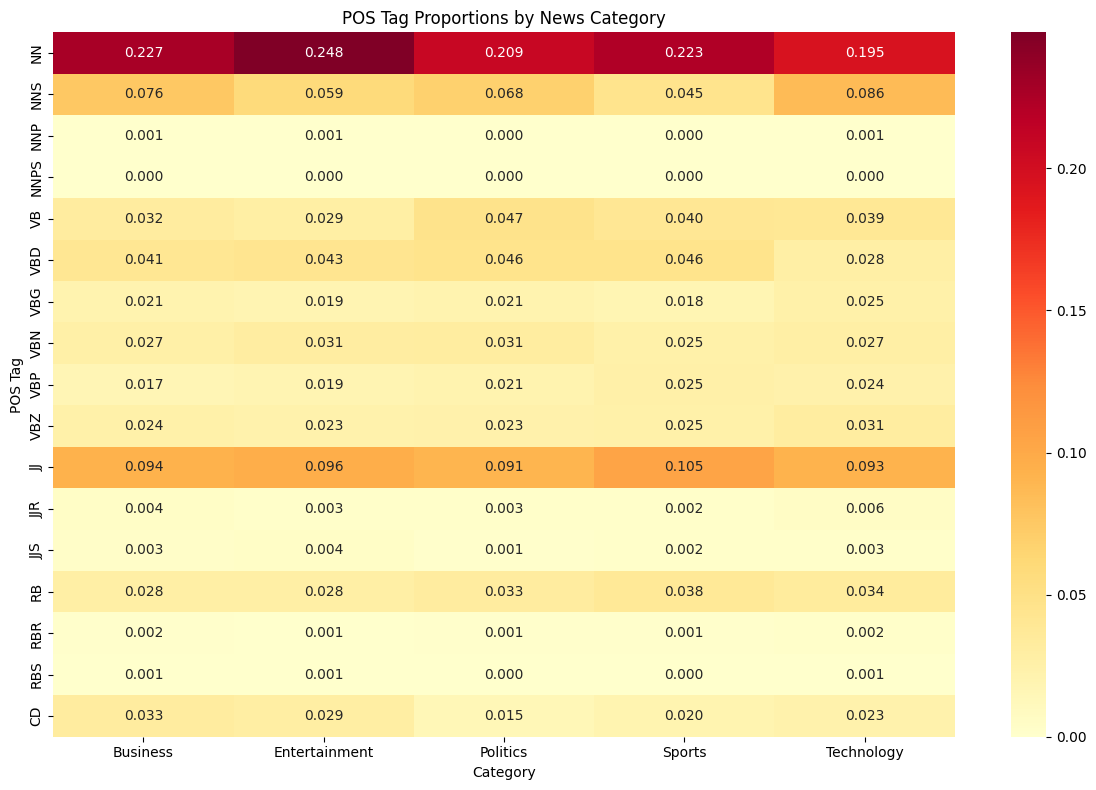


💡 ANALYSIS QUESTIONS:
1. Which category has the highest proportion of proper nouns (NNP/NNPS)?
   Answer: Business (0.1% of its words are proper nouns).
2. Which category uses the most action verbs (VB, VBD, VBG)?
   Answer: Politics (11.4% of its words are action verbs).
3. Are there interesting patterns in adjective (JJ) usage?
   Answer: Sports uses the most adjectives (11.0%) and Politics the fewest (9.5%).
4. How does number (CD) usage vary across categories?
   Answer: Business uses the most numbers (3.3%) and Politics the fewest (1.5%).
   Nouns vs verbs: Entertainment is the most noun-heavy, Politics the most verb-heavy.
   Hypothesis: Sports has the most action verbs? No. Business has the most numbers? Yes. Business has the most proper nouns? Yes.


In [10]:
# Analyze POS patterns by category
print("📊 POS PATTERNS BY CATEGORY")
print("=" * 50)

# Group by category and calculate mean proportions
pos_by_category = pos_df.groupby('category').mean()

# Focus on major POS categories
major_pos = ['NN', 'NNS', 'NNP', 'NNPS', 'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ',
             'JJ', 'JJR', 'JJS', 'RB', 'RBR', 'RBS', 'CD']

# Filter to only include major POS tags that exist in our data
available_pos = [pos for pos in major_pos if pos in pos_by_category.columns]

if available_pos:
    pos_summary = pos_by_category[available_pos]

    print("\n🎯 Key POS patterns by category:")
    print(pos_summary.round(4))

    # Create visualization
    plt.figure(figsize=(12, 8))
    sns.heatmap(pos_summary.T, annot=True, cmap='YlOrRd', fmt='.3f')
    plt.title('POS Tag Proportions by News Category')
    plt.xlabel('Category')
    plt.ylabel('POS Tag')
    plt.tight_layout()
    plt.show()

    # 💡 STUDENT TASK: Analyze the patterns
    # - Which categories use more nouns vs verbs?
    # - Do business articles have more numbers (CD)?
    # - Are there differences in adjective usage?

    print("\n💡 ANALYSIS QUESTIONS:")
    def _top(tags, low=False):
        cols = [t for t in tags if t in pos_by_category.columns]
        if not cols:
            return 'n/a', 0
        tot = pos_by_category[cols].sum(axis=1)
        return (tot.idxmin(), tot.min()) if low else (tot.idxmax(), tot.max())
    print("1. Which category has the highest proportion of proper nouns (NNP/NNPS)?")
    c, v = _top(['NNP', 'NNPS'])
    print(f"   Answer: {c} ({v:.1%} of its words are proper nouns).")
    print("2. Which category uses the most action verbs (VB, VBD, VBG)?")
    c, v = _top(['VB', 'VBD', 'VBG'])
    print(f"   Answer: {c} ({v:.1%} of its words are action verbs).")
    print("3. Are there interesting patterns in adjective (JJ) usage?")
    c, v = _top(['JJ', 'JJR', 'JJS'])
    lo, lv = _top(['JJ', 'JJR', 'JJS'], low=True)
    print(f"   Answer: {c} uses the most adjectives ({v:.1%}) and {lo} the fewest ({lv:.1%}).")
    print("4. How does number (CD) usage vary across categories?")
    c, v = _top(['CD'])
    lo, lv = _top(['CD'], low=True)
    print(f"   Answer: {c} uses the most numbers ({v:.1%}) and {lo} the fewest ({lv:.1%}).")

    # Student task + hypothesis: nouns vs verbs, sports verbs, business numbers/proper nouns
    nouns = pos_by_category[[t for t in ['NN', 'NNS', 'NNP', 'NNPS'] if t in pos_by_category.columns]].sum(axis=1)
    verbs = pos_by_category[[t for t in ['VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ'] if t in pos_by_category.columns]].sum(axis=1)
    ratio = nouns / verbs.replace(0, np.nan)
    print(f"   Nouns vs verbs: {ratio.idxmax()} is the most noun-heavy, {ratio.idxmin()} the most verb-heavy.")
    print(f"   Hypothesis: Sports has the most action verbs? {'Yes' if _top(['VB', 'VBD', 'VBG'])[0] == 'Sports' else 'No'}. "
          f"Business has the most numbers? {'Yes' if _top(['CD'])[0] == 'Business' else 'No'}. "
          f"Business has the most proper nouns? {'Yes' if _top(['NNP', 'NNPS'])[0] == 'Business' else 'No'}.")
else:
    print("⚠️ No major POS tags found in the analysis. Check your POS tagging implementation.")

## 🌳 Syntax Parsing and Semantic Analysis

### 🎯 Module 5: Understanding Sentence Structure

Now we'll use spaCy to perform dependency parsing and extract semantic relationships from our news articles. This helps us understand not just what words are present, but how they relate to each other.

**Dependency Parsing Applications:**
- **Relationship Extraction:** Find connections between entities
- **Event Detection:** Identify who did what to whom
- **Information Extraction:** Extract structured facts from unstructured text

**💡 Business Value:** Understanding sentence structure helps extract more precise information about events, relationships, and actions mentioned in news articles.

In [11]:
def extract_syntactic_features(text):
    """
    Extract syntactic features using spaCy dependency parsing

    💡 TIP: This function should extract:
    - Dependency relations
    - Subject-verb-object patterns
    - Noun phrases
    - Verb phrases
    """
    if not text or pd.isna(text):
        return {}

    # Process text with spaCy
    doc = nlp(str(text))

    features = {
        'num_sentences': len(list(doc.sents)),
        'num_tokens': len(doc),
        'dependency_relations': [],
        'noun_phrases': [],
        'verb_phrases': [],
        'subjects': [],
        'objects': []
    }

    # 🚀 YOUR CODE HERE: Extract syntactic features

    # Extract dependency relations
    for token in doc:
        if not token.is_space and not token.is_punct:
            features['dependency_relations'].append(token.dep_)

    # Extract noun phrases
    for chunk in doc.noun_chunks:
        features['noun_phrases'].append(chunk.text.lower())

    # Extract subjects and objects
    for token in doc:
        if token.dep_ in ['nsubj', 'nsubjpass']:  # Subjects
            features['subjects'].append(token.text.lower())
        elif token.dep_ in ['dobj', 'iobj', 'pobj']:  # Objects
            features['objects'].append(token.text.lower())

    # Count dependency types
    dep_counts = Counter(features['dependency_relations'])
    features['dependency_counts'] = dict(dep_counts)

    return features

# Apply syntactic analysis to sample articles
print("🌳 Performing syntactic analysis...")

# Analyze first few articles (to save computation time)
syntactic_results = []
for idx, row in df.head(5).iterrows():  # Limit to first 5 for demo
    features = extract_syntactic_features(row['full_text'])
    features['category'] = row['category']
    features['article_id'] = row['article_id']
    syntactic_results.append(features)

print("✅ Syntactic analysis complete!")

# Display results
for i, result in enumerate(syntactic_results):
    print(f"\n📰 Article {i+1} ({result['category']}):")
    print(f"  Sentences: {result['num_sentences']}")
    print(f"  Tokens: {result['num_tokens']}")
    print(f"  Noun phrases: {result['noun_phrases'][:3]}...")  # Show first 3
    print(f"  Subjects: {result['subjects'][:3]}...")  # Show first 3
    print(f"  Objects: {result['objects'][:3]}...")  # Show first 3

🌳 Performing syntactic analysis...
✅ Syntactic analysis complete!

📰 Article 1 (Business):
  Sentences: 10
  Tokens: 238
  Noun phrases: ['nasdaq', '$100m share sale', 'the owner']...
  Subjects: ['nasdaq', 'owner', 'it']...
  Objects: ['sale', 'nasdaq', 'index']...

📰 Article 2 (Business):
  Sentences: 13
  Tokens: 346
  Noun phrases: ['india s deccan', '$1.8bn deal air deccan', 'india s deccan']...
  Subjects: ['deccan', 'deccan', 'deccan']...
  Objects: ['deccan', 'planes', 'deal']...

📰 Article 3 (Business):
  Sentences: 9
  Tokens: 236
  Noun phrases: ['saudi ministry', 'women women', 'saudi ministry']...
  Subjects: ['ministry', 'women', 'women']...
  Objects: ['ministry', 'ministry', 'time']...

📰 Article 4 (Business):
  Sentences: 8
  Tokens: 254
  Noun phrases: ['strong demand', 'oil rally crude oil prices', 'strong demand']...
  Subjects: ['demand', 'prices', 'demand']...
  Objects: ['47', 'thursday', 'forecasts']...

📰 Article 5 (Business):
  Sentences: 19
  Tokens: 466
  No

In [12]:
# Visualize dependency parsing for a sample sentence
from spacy import displacy

# Choose a sample sentence
sample_sentence = df.iloc[0]['content']  # First article's content
print(f"📝 Sample sentence: {sample_sentence}")

# Process with spaCy
doc = nlp(sample_sentence)

# Display dependency tree (this works best in Jupyter)
print("\n🌳 Dependency Parse Visualization:")
try:
    # This will create an interactive visualization in Jupyter
    displacy.render(doc, style="dep", jupyter=True)
except:
    # Fallback: print dependency information
    print("\n🔗 Dependency Relations:")
    for token in doc:
        if not token.is_space and not token.is_punct:
            print(f"  {token.text} --> {token.dep_} --> {token.head.text}")

# 💡 STUDENT TASK: Extend syntactic analysis
# - Compare syntactic complexity across categories
# - Extract action patterns (who did what)
# - Identify most common dependency relations per category
# - Create features for classification based on syntax

# ➕ ADDED (Module 5 tasks)
# Task 1: compare syntactic complexity across categories (all articles)
syn_rows = []
for _, r in df.iterrows():
    f = extract_syntactic_features(r['full_text'])
    d = nlp(str(r['full_text']))
    n_sent = max(f['num_sentences'], 1)
    syn_rows.append({'category': r['category'],
                     'avg_sentence_len': f['num_tokens'] / n_sent,
                     'noun_phrases_per_sentence': len(f['noun_phrases']) / n_sent,
                     'max_tree_depth': max(len(list(t.ancestors)) for t in d),
                     'dep_counts': f['dependency_counts']})
syn_df = pd.DataFrame(syn_rows)
complexity = syn_df.groupby('category')[['avg_sentence_len', 'noun_phrases_per_sentence', 'max_tree_depth']].mean().round(2)
print("\n📊 Syntactic complexity by category:")
print(complexity)
print(f"Answer: {complexity['avg_sentence_len'].idxmax()} has the longest sentences and {complexity['max_tree_depth'].idxmax()} the deepest parse trees.")

# Task 2: action patterns (who did what)
actions = []
for _, r in df.iterrows():
    for tok in nlp(str(r['full_text'])):
        if tok.pos_ == 'VERB':
            subj = [w.text for w in tok.children if w.dep_ in ('nsubj', 'nsubjpass')]
            obj = [w.text for w in tok.children if w.dep_ in ('dobj', 'attr')]
            if subj and obj:
                actions.append((r['category'], subj[0], tok.lemma_, obj[0]))
print("\n🎬 Who did what (first 10):")
for cat, who, verb, what in actions[:10]:
    print(f"  [{cat}] {who} --{verb}--> {what}")

# Task 3: most common dependency relations per category
dep_by_cat = {}
for cat, grp in syn_df.groupby('category'):
    total = Counter()
    for dc in grp['dep_counts']:
        total.update(dc)
    dep_by_cat[cat] = total
print("\n🔗 Most common dependency relations per category:")
for cat, cnt in dep_by_cat.items():
    print(f"  {cat}: " + ", ".join(f"{d} ({n})" for d, n in cnt.most_common(5)))

# Task 4: syntax features for classification (one row per article, same order as df)
key_deps = ['nsubj', 'dobj', 'pobj', 'prep', 'amod', 'compound', 'nummod', 'det', 'aux', 'advmod']
dep_share = pd.DataFrame([{f'dep_{d}': dc.get(d, 0) / max(sum(dc.values()), 1) for d in key_deps}
                          for dc in syn_df['dep_counts']])
syntax_features = pd.concat([syn_df[['avg_sentence_len', 'noun_phrases_per_sentence', 'max_tree_depth']].reset_index(drop=True),
                             dep_share], axis=1)
print(f"\n🧩 Syntax features for classification: {syntax_features.shape[0]} articles x {syntax_features.shape[1]} features")

📝 Sample sentence: nasdaq planning $100m share sale the owner of the technology-dominated nasdaq stock index plans to sell shares to the public and list itself on the market it operates.  according to a registration document filed with the securities and exchange commission  nasdaq stock market plans to raise $100m (£52m) from the sale. some observers see this as another step closer to a full public listing. however nasdaq  an icon of the 1990s technology boom  recently poured cold water on those suggestions.  the company first sold shares in private placements during 2000 and 2001. it technically went public in 2002 when the stock started trading on the otc bulletin board  which lists equities that trade only occasionally. nasdaq will not make money from the sale  only investors who bought shares in the private placings  the filing documents said. the nasdaq is made up shares in technology firms and other companies with high growth potential. it was the most potent symbol of the 1990s


📊 Syntactic complexity by category:
               avg_sentence_len  noun_phrases_per_sentence  max_tree_depth
category                                                                  
Business                  25.78                       5.80           10.82
Entertainment             25.71                       5.80           10.52
Politics                  26.11                       6.15           11.61
Sports                    23.25                       5.30            9.66
Technology                25.14                       5.94           11.52
Answer: Politics has the longest sentences and Politics the deepest parse trees.

🎬 Who did what (first 10):
  [Business] nasdaq --plan--> sale
  [Business] observers --see--> this
  [Business] nasdaq --pour--> water
  [Business] company --sell--> shares
  [Business] which --list--> equities
  [Business] nasdaq --make--> money
  [Business] who --buy--> shares
  [Business] nasdaq --make--> shares
  [Business] deccan --order--> deccan
 

## 😊 Sentiment and Emotion Analysis

### 🎯 Module 6: Understanding Emotional Tone

Let's analyze the sentiment and emotional tone of our news articles. This can reveal interesting patterns about how different types of news are presented and perceived.

**Sentiment Analysis Applications:**
- **Media Bias Detection:** Identify emotional slant in news coverage
- **Public Opinion Tracking:** Monitor sentiment trends over time
- **Content Recommendation:** Suggest articles based on emotional tone

**💡 Hypothesis:** Different news categories might have different emotional profiles - sports might be more positive, politics more negative, etc.

In [13]:
# Initialize sentiment analyzer
sia = SentimentIntensityAnalyzer()

def analyze_sentiment(text):
    """
    Analyze sentiment using VADER sentiment analyzer

    💡 TIP: VADER returns:
    - compound: overall sentiment (-1 to 1)
    - pos: positive score (0 to 1)
    - neu: neutral score (0 to 1)
    - neg: negative score (0 to 1)
    """
    if not text or pd.isna(text):
        return {'compound': 0, 'pos': 0, 'neu': 1, 'neg': 0}

    # 🚀 YOUR CODE HERE: Implement sentiment analysis
    scores = sia.polarity_scores(str(text))

    # Add interpretation
    if scores['compound'] >= 0.05:
        scores['sentiment_label'] = 'positive'
    elif scores['compound'] <= -0.05:
        scores['sentiment_label'] = 'negative'
    else:
        scores['sentiment_label'] = 'neutral'

    return scores

# Apply sentiment analysis to all articles
print("😊 Analyzing sentiment...")

sentiment_results = []
for idx, row in df.iterrows():
    # Analyze both title and content
    title_sentiment = analyze_sentiment(row['title'])
    content_sentiment = analyze_sentiment(row['content'])
    full_sentiment = analyze_sentiment(row['full_text'])

    result = {
        'article_id': row['article_id'],
        'category': row['category'],
        'title_sentiment': title_sentiment['compound'],
        'title_label': title_sentiment['sentiment_label'],
        'content_sentiment': content_sentiment['compound'],
        'content_label': content_sentiment['sentiment_label'],
        'full_sentiment': full_sentiment['compound'],
        'full_label': full_sentiment['sentiment_label'],
        'pos_score': full_sentiment['pos'],
        'neu_score': full_sentiment['neu'],
        'neg_score': full_sentiment['neg']
    }
    sentiment_results.append(result)

# Convert to DataFrame
sentiment_df = pd.DataFrame(sentiment_results)

print("✅ Sentiment analysis complete!")
print(f"📊 Analyzed {len(sentiment_df)} articles")

# Display sample results
print("\n📝 Sample sentiment results:")
print(sentiment_df[['category', 'full_sentiment', 'full_label']].head())

😊 Analyzing sentiment...
✅ Sentiment analysis complete!
📊 Analyzed 600 articles

📝 Sample sentiment results:
   category  full_sentiment full_label
0  Business          0.9524   positive
1  Business          0.9670   positive
2  Business          0.2617   positive
3  Business         -0.9186   negative
4  Business          0.5131   positive


📊 SENTIMENT ANALYSIS BY CATEGORY

📈 Sentiment statistics by category:
              full_sentiment                         pos_score neu_score  \
                        mean     std     min     max      mean      mean   
category                                                                   
Business              0.2099  0.8664 -0.9973  0.9980    0.0915    0.8365   
Entertainment         0.6067  0.6625 -0.9978  0.9999    0.1286    0.8180   
Politics              0.1191  0.8980 -0.9984  0.9999    0.0967    0.8153   
Sports                0.5275  0.7650 -0.9958  0.9996    0.1379    0.7926   
Technology            0.5964  0.6922 -0.9986  0.9993    0.0912    0.8617   

              neg_score  
                   mean  
category                 
Business         0.0719  
Entertainment    0.0533  
Politics         0.0880  
Sports           0.0695  
Technology       0.0471  

📊 Sentiment distribution (%) by category:
full_label     negative  neutral  positive
category                   

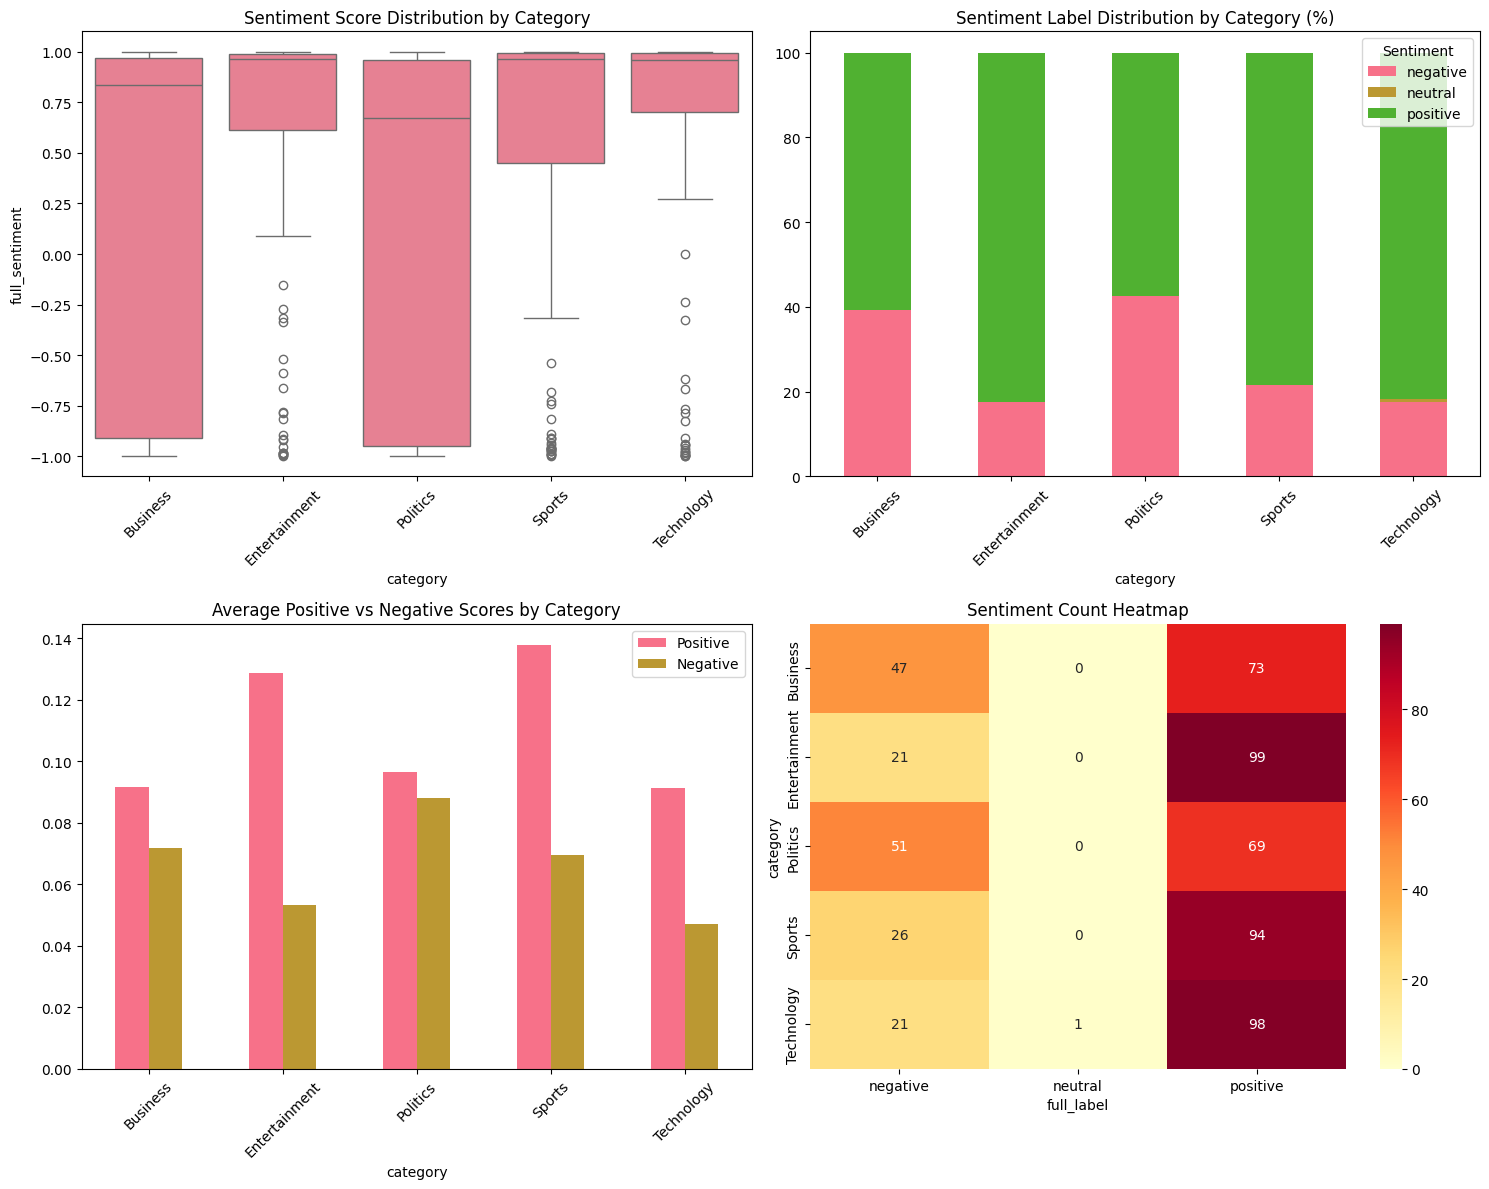


💡 ANSWERS
1. Which categories are most positive/negative? Most positive: Entertainment (+0.61); most negative: Politics (+0.12).
2. Do title and content sentiment differ? Content is +0.39 compared with titles on average, and the labels disagree in 55% of articles.
3. How does sentiment vary within categories? Most varied: Politics (std 0.90); most consistent: Entertainment (std 0.66).
4. Can sentiment be a classification feature? Alone it gets 32% accuracy (chance is 20%), so it helps, but works best combined with TF-IDF.
Hypothesis (sports more positive, politics more negative): Sports ranks 3 of 5, Politics ranks 5 -> supported.


In [14]:
# Analyze sentiment patterns by category
print("📊 SENTIMENT ANALYSIS BY CATEGORY")
print("=" * 50)

# Calculate sentiment statistics by category
sentiment_by_category = sentiment_df.groupby('category').agg({
    'full_sentiment': ['mean', 'std', 'min', 'max'],
    'pos_score': 'mean',
    'neu_score': 'mean',
    'neg_score': 'mean'
}).round(4)

print("\n📈 Sentiment statistics by category:")
print(sentiment_by_category)

# Sentiment distribution by category
sentiment_dist = sentiment_df.groupby(['category', 'full_label']).size().unstack(fill_value=0)
sentiment_dist_pct = sentiment_dist.div(sentiment_dist.sum(axis=1), axis=0) * 100

print("\n📊 Sentiment distribution (%) by category:")
print(sentiment_dist_pct.round(2))

# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Sentiment scores by category
sns.boxplot(data=sentiment_df, x='category', y='full_sentiment', ax=axes[0,0])
axes[0,0].set_title('Sentiment Score Distribution by Category')
axes[0,0].tick_params(axis='x', rotation=45)

# 2. Sentiment label distribution
sentiment_dist_pct.plot(kind='bar', ax=axes[0,1], stacked=True)
axes[0,1].set_title('Sentiment Label Distribution by Category (%)')
axes[0,1].tick_params(axis='x', rotation=45)
axes[0,1].legend(title='Sentiment')

# 3. Positive vs Negative scores
category_means = sentiment_df.groupby('category')[['pos_score', 'neg_score']].mean()
category_means.plot(kind='bar', ax=axes[1,0])
axes[1,0].set_title('Average Positive vs Negative Scores by Category')
axes[1,0].tick_params(axis='x', rotation=45)
axes[1,0].legend(['Positive', 'Negative'])

# 4. Sentiment vs Category heatmap
sentiment_pivot = sentiment_df.pivot_table(values='full_sentiment', index='category',
                                         columns='full_label', aggfunc='count', fill_value=0)
sns.heatmap(sentiment_pivot, annot=True, fmt='d', ax=axes[1,1], cmap='YlOrRd')
axes[1,1].set_title('Sentiment Count Heatmap')

plt.tight_layout()
plt.show()

# 💡 STUDENT TASK: Analyze sentiment patterns
# - Which categories are most positive/negative?
# - Are there differences between title and content sentiment?
# - How does sentiment vary within categories?
# - Can sentiment be used as a feature for classification?

# ➕ ADDED (Module 6 questions and hypothesis)
m = sentiment_df.groupby('category')['full_sentiment'].mean()
print("\n💡 ANSWERS")
print(f"1. Which categories are most positive/negative? Most positive: {m.idxmax()} ({m.max():+.2f}); most negative: {m.idxmin()} ({m.min():+.2f}).")
diff = (sentiment_df['content_sentiment'] - sentiment_df['title_sentiment']).mean()
disagree = (sentiment_df['title_label'] != sentiment_df['content_label']).mean()
print(f"2. Do title and content sentiment differ? Content is {diff:+.2f} compared with titles on average, and the labels disagree in {disagree:.0%} of articles.")
sd = sentiment_df.groupby('category')['full_sentiment'].std()
print(f"3. How does sentiment vary within categories? Most varied: {sd.idxmax()} (std {sd.max():.2f}); most consistent: {sd.idxmin()} (std {sd.min():.2f}).")
k = min(3, sentiment_df['category'].value_counts().min())
if k >= 2:
    acc = cross_val_score(LogisticRegression(max_iter=1000),
                          sentiment_df[['full_sentiment', 'pos_score', 'neu_score', 'neg_score']],
                          sentiment_df['category'], cv=k).mean()
    chance = 1 / sentiment_df['category'].nunique()
    verdict = "it helps, but works best combined with TF-IDF" if acc > chance + 0.1 else "it adds little on its own"
    print(f"4. Can sentiment be a classification feature? Alone it gets {acc:.0%} accuracy (chance is {chance:.0%}), so {verdict}.")
ranked = list(m.sort_values(ascending=False).index)
if 'Sports' in ranked and 'Politics' in ranked:
    ok = ranked.index('Sports') < ranked.index('Politics')
    print(f"Hypothesis (sports more positive, politics more negative): Sports ranks {ranked.index('Sports') + 1} of {len(ranked)}, "
          f"Politics ranks {ranked.index('Politics') + 1} -> {'supported' if ok else 'not supported'}.")

## 🏷️ Text Classification System

### 🎯 Module 7: Building the News Classifier

Now we'll build the core of our NewsBot system - a multi-class text classifier that can automatically categorize news articles. We'll compare different algorithms and evaluate their performance.

**Classification Pipeline:**
1. **Feature Engineering:** Combine TF-IDF with other features
2. **Model Training:** Train multiple algorithms
3. **Model Evaluation:** Compare performance metrics
4. **Model Selection:** Choose the best performing model

**💡 Business Impact:** Accurate classification enables automatic content routing, personalized recommendations, and efficient content management.

In [15]:
# Prepare features for classification
print("🔧 Preparing features for classification...")

# 💡 TIP: Combine multiple feature types for better performance
# - TF-IDF features (most important)
# - Sentiment features
# - Text length features
# - POS features (if available)

# Create feature matrix
X_tfidf = tfidf_matrix.toarray()  # TF-IDF features

# Add sentiment features
sentiment_features = sentiment_df[['full_sentiment', 'pos_score', 'neu_score', 'neg_score']].values

# Add text length features
length_features = np.array([
    df['full_text'].str.len(),  # Character length
    df['full_text'].str.split().str.len(),  # Word count
    df['title'].str.len(),  # Title length
]).T

# 🚀 YOUR CODE HERE: Combine all features
X_combined = np.hstack([
    X_tfidf,
    sentiment_features,
    length_features
])

# Target variable
y = df['category'].values

print(f"✅ Feature matrix prepared!")
print(f"📊 Feature matrix shape: {X_combined.shape}")
print(f"🎯 Number of classes: {len(np.unique(y))}")
print(f"📋 Classes: {np.unique(y)}")

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_combined, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\n📈 Data split:")
print(f"  Training set: {X_train.shape[0]} samples")
print(f"  Test set: {X_test.shape[0]} samples")

# ➕ ADDED: scale the sentiment/length columns to 0-1 (Naive Bayes cannot take negative values)
from sklearn.preprocessing import MinMaxScaler
n_tfidf = X_tfidf.shape[1]
scaler = MinMaxScaler().fit(X_train[:, n_tfidf:])
X_train[:, n_tfidf:] = scaler.transform(X_train[:, n_tfidf:])
X_test[:, n_tfidf:] = np.clip(scaler.transform(X_test[:, n_tfidf:]), 0, 1)

🔧 Preparing features for classification...
✅ Feature matrix prepared!
📊 Feature matrix shape: (600, 5007)
🎯 Number of classes: 5
📋 Classes: ['Business' 'Entertainment' 'Politics' 'Sports' 'Technology']

📈 Data split:
  Training set: 480 samples
  Test set: 120 samples


In [16]:
# Train and evaluate multiple classifiers
print("🤖 Training multiple classifiers...")

# Define classifiers to compare
classifiers = {
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'SVM': SVC(random_state=42, probability=True)  # Enable probability for better analysis
}

# 💡 TIP: For larger datasets, you might want to use SGDClassifier for efficiency
# from sklearn.linear_model import SGDClassifier
# classifiers['SGD'] = SGDClassifier(random_state=42)

# Train and evaluate each classifier
results = {}
trained_models = {}

for name, classifier in classifiers.items():
    print(f"\n🔄 Training {name}...")

    # 🚀 YOUR CODE HERE: Train and evaluate classifier
    # Train the model
    classifier.fit(X_train, y_train)

    # Make predictions
    y_pred = classifier.predict(X_test)
    y_pred_proba = classifier.predict_proba(X_test) if hasattr(classifier, 'predict_proba') else None

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    # Cross-validation score
    cv_scores = cross_val_score(classifier, X_train, y_train, cv=3, scoring='accuracy')

    # Store results
    results[name] = {
        'accuracy': accuracy,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std(),
        'predictions': y_pred,
        'probabilities': y_pred_proba
    }

    trained_models[name] = classifier

    print(f"  ✅ Accuracy: {accuracy:.4f}")
    print(f"  📊 CV Score: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

print("\n🏆 CLASSIFIER COMPARISON")
print("=" * 50)
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Test Accuracy': [results[name]['accuracy'] for name in results.keys()],
    'CV Mean': [results[name]['cv_mean'] for name in results.keys()],
    'CV Std': [results[name]['cv_std'] for name in results.keys()]
})

print(comparison_df.round(4))

# Find best model
best_model_name = comparison_df.loc[comparison_df['Test Accuracy'].idxmax(), 'Model']
print(f"\n🥇 Best performing model: {best_model_name}")

🤖 Training multiple classifiers...

🔄 Training Naive Bayes...
  ✅ Accuracy: 0.9417
  📊 CV Score: 0.9521 (+/- 0.0212)

🔄 Training Logistic Regression...
  ✅ Accuracy: 0.9250
  📊 CV Score: 0.9167 (+/- 0.0257)

🔄 Training SVM...
  ✅ Accuracy: 0.9083
  📊 CV Score: 0.9021 (+/- 0.0482)

🏆 CLASSIFIER COMPARISON
                 Model  Test Accuracy  CV Mean  CV Std
0          Naive Bayes         0.9417   0.9521  0.0106
1  Logistic Regression         0.9250   0.9167  0.0128
2                  SVM         0.9083   0.9021  0.0241

🥇 Best performing model: Naive Bayes


📊 DETAILED EVALUATION: Naive Bayes

📋 Classification Report:
               precision    recall  f1-score   support

     Business       0.95      0.83      0.89        24
Entertainment       0.96      0.92      0.94        24
     Politics       0.96      0.96      0.96        24
       Sports       1.00      1.00      1.00        24
   Technology       0.86      1.00      0.92        24

     accuracy                           0.94       120
    macro avg       0.94      0.94      0.94       120
 weighted avg       0.94      0.94      0.94       120



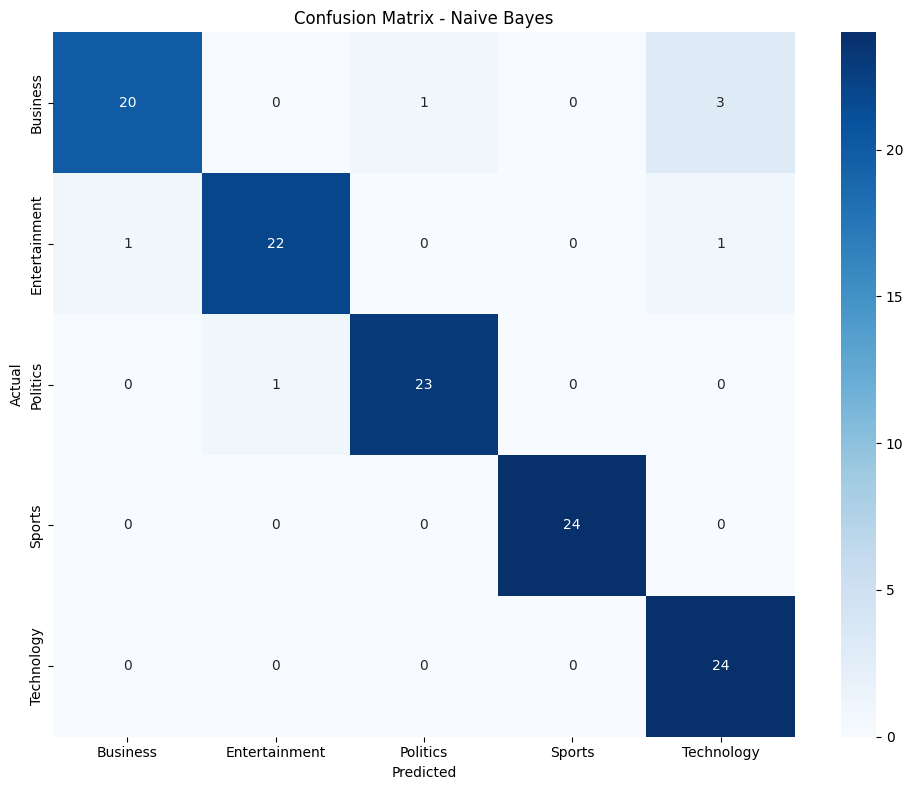


🔬 Feature combinations (Logistic Regression test accuracy):
  TF-IDF only: 0.942
  TF-IDF + sentiment/length: 0.925
  TF-IDF + syntax: 0.908
  All features: 0.858

⚙️ Tuned Logistic Regression: best C = 10, CV 0.946, test 0.958

⚖️ Class balance: {'Business': 120, 'Entertainment': 120, 'Politics': 120, 'Sports': 120, 'Technology': 120} (largest/smallest = 1.0)
  class_weight=None: accuracy 0.925, macro F1 0.925
  class_weight=balanced: accuracy 0.925, macro F1 0.925


In [17]:
# Detailed evaluation of the best model
best_model = trained_models[best_model_name]
best_predictions = results[best_model_name]['predictions']

print(f"📊 DETAILED EVALUATION: {best_model_name}")
print("=" * 60)

# Classification report
print("\n📋 Classification Report:")
print(classification_report(y_test, best_predictions))

# Confusion matrix
cm = confusion_matrix(y_test, best_predictions)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# Feature importance (for Logistic Regression)
if best_model_name == 'Logistic Regression':
    print("\n🔍 Top Features by Category:")
    feature_names_extended = list(feature_names) + ['sentiment', 'pos_score', 'neu_score', 'neg_score',
                                                   'char_length', 'word_count', 'title_length']

    classes = best_model.classes_
    coefficients = best_model.coef_

    for i, class_name in enumerate(classes):
        top_indices = np.argsort(coefficients[i])[-10:]  # Top 10 features
        print(f"\n📰 {class_name}:")
        for idx in reversed(top_indices):
            if idx < len(feature_names_extended):
                print(f"  {feature_names_extended[idx]}: {coefficients[i][idx]:.4f}")

# 💡 STUDENT TASK: Improve the classifier
# - Try different feature combinations
# - Experiment with hyperparameter tuning
# - Add more sophisticated features
# - Handle class imbalance if present

# ➕ ADDED (Module 7 tasks: feature combinations, tuning, class imbalance)
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import f1_score

idx_tr, idx_te = train_test_split(np.arange(len(y)), test_size=0.2, random_state=42, stratify=y)
def _scale(block):
    block = np.asarray(block, dtype=float)
    return np.clip(MinMaxScaler().fit(block[idx_tr]).transform(block), 0, 1)
extra_s = _scale(np.hstack([sentiment_features, length_features]))
syntax_s = _scale(syntax_features.values)
feature_sets = {
    'TF-IDF only': X_tfidf,
    'TF-IDF + sentiment/length': np.hstack([X_tfidf, extra_s]),
    'TF-IDF + syntax': np.hstack([X_tfidf, syntax_s]),
    'All features': np.hstack([X_tfidf, extra_s, syntax_s]),
}
print("\n🔬 Feature combinations (Logistic Regression test accuracy):")
for name, Xf in feature_sets.items():
    lr = LogisticRegression(max_iter=2000, random_state=42).fit(Xf[idx_tr], y[idx_tr])
    print(f"  {name}: {accuracy_score(y[idx_te], lr.predict(Xf[idx_te])):.3f}")

cv_k = min(3, pd.Series(y_train).value_counts().min())
grid = GridSearchCV(LogisticRegression(max_iter=2000, random_state=42), {'C': [0.1, 1, 10, 100]}, cv=cv_k)
grid.fit(X_train, y_train)
print(f"\n⚙️ Tuned Logistic Regression: best C = {grid.best_params_['C']}, CV {grid.best_score_:.3f}, test {accuracy_score(y_test, grid.predict(X_test)):.3f}")

counts = pd.Series(y).value_counts()
print(f"\n⚖️ Class balance: {counts.to_dict()} (largest/smallest = {counts.max() / counts.min():.1f})")
for cw in [None, 'balanced']:
    p = LogisticRegression(max_iter=2000, random_state=42, class_weight=cw).fit(X_train, y_train).predict(X_test)
    print(f"  class_weight={cw}: accuracy {accuracy_score(y_test, p):.3f}, macro F1 {f1_score(y_test, p, average='macro'):.3f}")

## 🔍 Named Entity Recognition

### 🎯 Module 8: Extracting Facts from News

Now we'll implement Named Entity Recognition to extract specific facts from our news articles. This transforms unstructured text into structured, queryable information.

**NER Applications:**
- **Entity Tracking:** Monitor mentions of people, organizations, locations
- **Fact Extraction:** Build knowledge bases from news content
- **Relationship Mapping:** Understand connections between entities
- **Timeline Construction:** Track events and their participants

**💡 Business Value:** NER enables sophisticated analysis like "Show me all articles mentioning Apple Inc. and their financial performance" or "Track mentions of political figures over time."

In [18]:
def extract_entities(text):
    """
    Extract named entities using spaCy

    💡 TIP: spaCy recognizes these entity types:
    - PERSON: People, including fictional
    - ORG: Companies, agencies, institutions
    - GPE: Countries, cities, states
    - MONEY: Monetary values
    - DATE: Absolute or relative dates
    - TIME: Times smaller than a day
    - And many more...
    """
    if not text or pd.isna(text):
        return []

    # 🚀 YOUR CODE HERE: Implement entity extraction
    doc = nlp(str(text))

    entities = []
    for ent in doc.ents:
        entities.append({
            'text': ent.text,
            'label': ent.label_,
            'start': ent.start_char,
            'end': ent.end_char,
            'description': spacy.explain(ent.label_)
        })

    return entities

# Apply NER to all articles
print("🔍 Extracting named entities...")

all_entities = []
article_entities = []

for idx, row in df.iterrows():
    entities = extract_entities(row['full_text'])

    # Store entities for this article
    article_entities.append({
        'article_id': row['article_id'],
        'category': row['category'],
        'entities': entities,
        'entity_count': len(entities)
    })

    # Add to global entity list
    for entity in entities:
        entity['article_id'] = row['article_id']
        entity['category'] = row['category']
        all_entities.append(entity)

print(f"✅ Entity extraction complete!")
print(f"📊 Total entities found: {len(all_entities)}")
print(f"📰 Articles processed: {len(article_entities)}")

# Convert to DataFrame for analysis
entities_df = pd.DataFrame(all_entities)

if not entities_df.empty:
    print(f"\n🏷️ Entity types found: {entities_df['label'].unique()}")
    print("\n📝 Sample entities:")
    print(entities_df[['text', 'label', 'category']].head(10))
else:
    print("⚠️ No entities found. This might happen with very short sample texts.")

🔍 Extracting named entities...
✅ Entity extraction complete!
📊 Total entities found: 17763
📰 Articles processed: 600

🏷️ Entity types found: ['ORG' 'MONEY' 'DATE' 'GPE' 'NORP' 'CARDINAL' 'PRODUCT' 'ORDINAL' 'PERSON'
 'PERCENT' 'QUANTITY' 'LOC' 'TIME' 'FAC' 'LAW' 'EVENT' 'LANGUAGE'
 'WORK_OF_ART']

📝 Sample entities:
                                     text  label  category
0                                  nasdaq    ORG  Business
1                                     100  MONEY  Business
2                                     100  MONEY  Business
3  the securities and exchange commission    ORG  Business
4                                   $100m  MONEY  Business
5                                      52  MONEY  Business
6                                   1990s   DATE  Business
7                                    2000   DATE  Business
8                                    2001   DATE  Business
9                                    2002   DATE  Business


📊 NAMED ENTITY ANALYSIS

🏷️ Entity type distribution:
label
DATE           3693
PERSON         3395
CARDINAL       2687
GPE            2311
ORG            1857
NORP           1203
ORDINAL         717
MONEY           703
PERCENT         545
TIME            242
LOC             210
QUANTITY         74
LANGUAGE         32
PRODUCT          31
FAC              26
EVENT            18
LAW              16
WORK_OF_ART       3
Name: count, dtype: int64

📰 Entity types by news category:
label          CARDINAL  DATE  EVENT  FAC  GPE  LANGUAGE  LAW  LOC  MONEY  \
category                                                                    
Business            388   904      0    6  605         0    5   65    309   
Entertainment       502   774      3    5  322         7    2   25    190   
Politics            421   626     12    5  392         7    3   61    101   
Sports              713   739      3    8  570         2    1   13     12   
Technology          663   650      0    2  422        16  

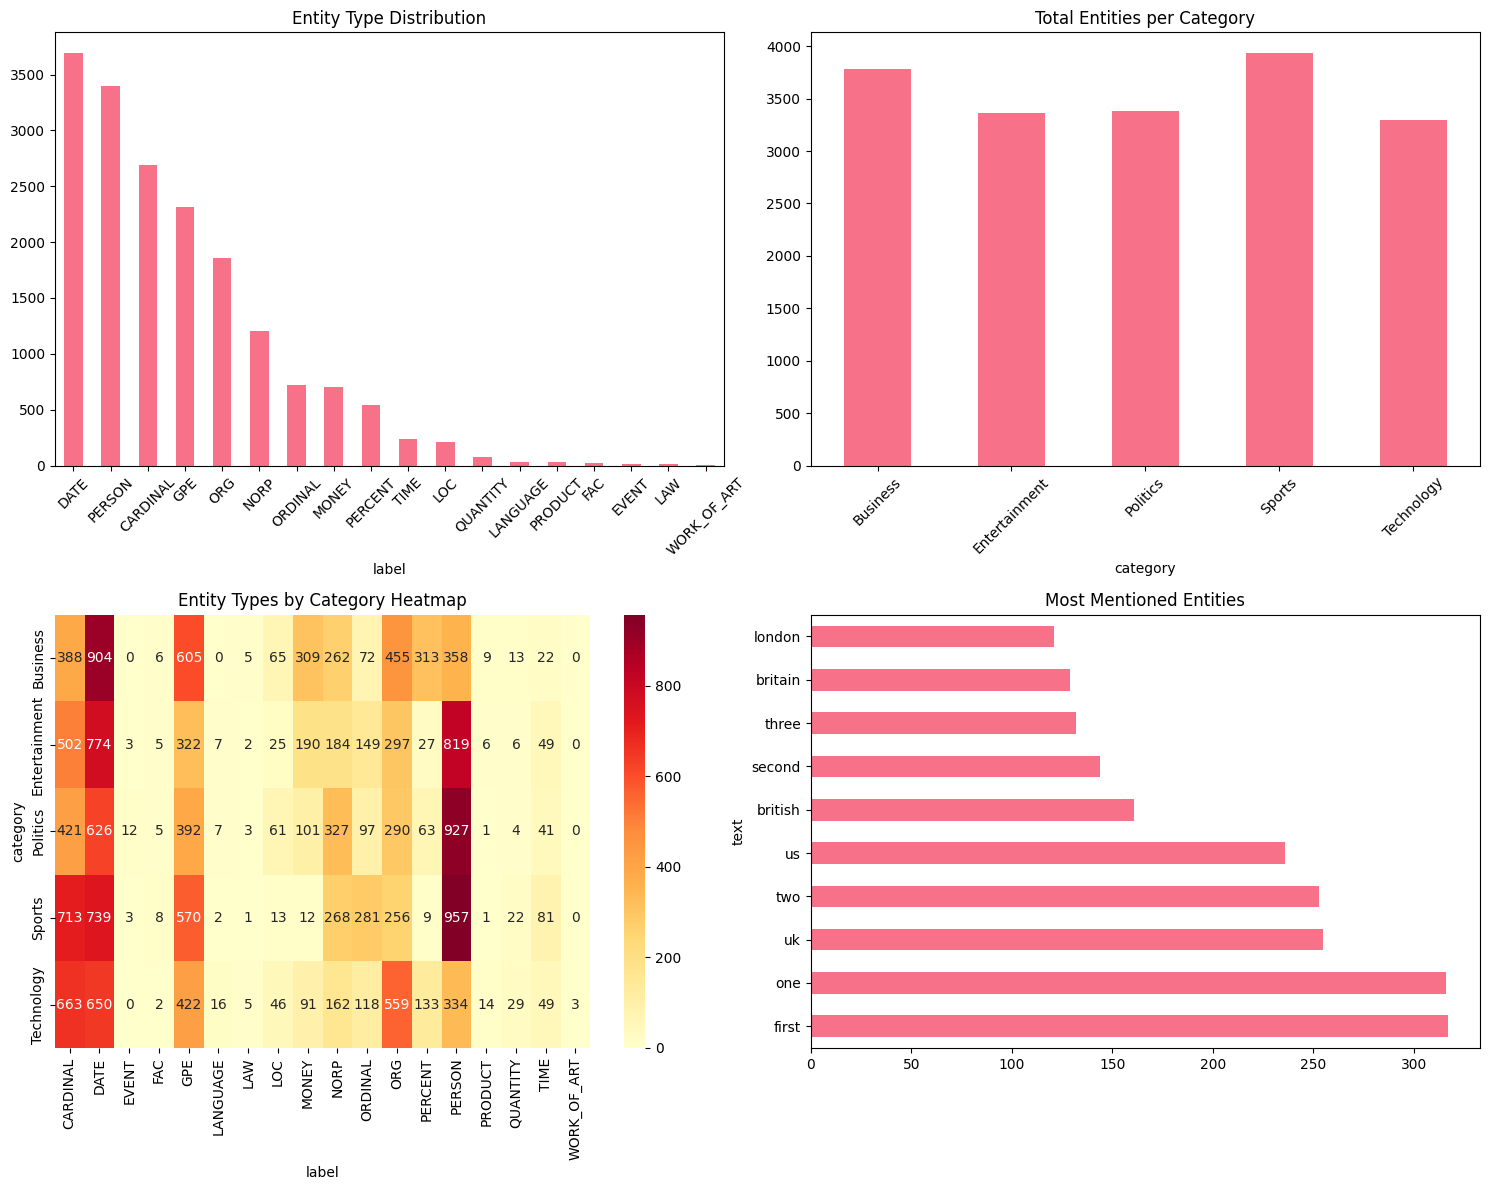


🔗 Entities that appear together:
  britain + uk: 38
  uk + us: 32
  london + uk: 27
  blair + tony blair: 25
  britain + tony blair: 17
  michael howard + tony blair: 17
  new york + us: 15
  bbc + britain: 14


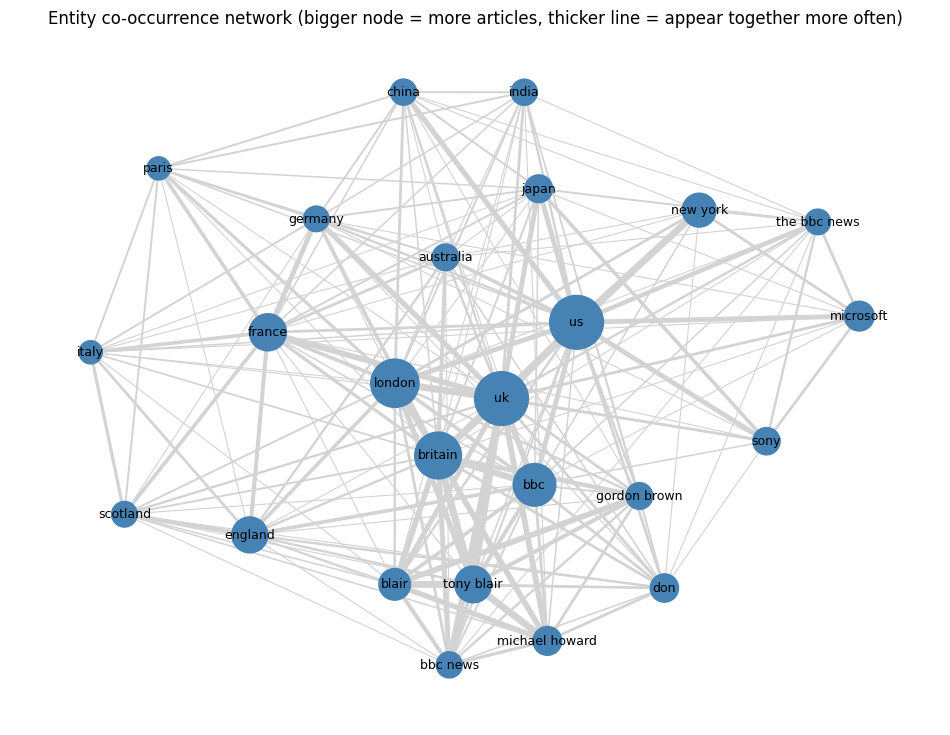


📅 Mentions per date for the 5 most mentioned entities:
text        first  one  two   uk   us
date                                 
2024-01-15    317  316  253  255  236

🕸️ Entity relationships:
  india --seal--> airbus
  uk --set--> richard branson
  agence france presse --build--> germany
  saudi ministry --employ--> saudi arabia s
  paris --say--> china
  the us department of energy --report--> yukos
  john reade --happen--> ubs
  us --say--> treasury
  uk --say--> lena komileva
  pwc s --say--> samuel

😞 Most negative entities: sam raimi (-0.98), s  bullying (-0.97), germaine greer (-0.97)
😊 Most positive entities: stephen mear (+1.00), michelle kelly (+1.00), william shakespeare (+1.00)


In [19]:
# Analyze entity patterns
if not entities_df.empty:
    print("📊 NAMED ENTITY ANALYSIS")
    print("=" * 50)

    # Entity type distribution
    entity_counts = entities_df['label'].value_counts()
    print("\n🏷️ Entity type distribution:")
    print(entity_counts)

    # Entity types by category
    entity_by_category = entities_df.groupby(['category', 'label']).size().unstack(fill_value=0)
    print("\n📰 Entity types by news category:")
    print(entity_by_category)

    # Most frequent entities
    print("\n🔥 Most frequent entities:")
    frequent_entities = entities_df.groupby(['text', 'label']).size().sort_values(ascending=False).head(15)
    for (entity, label), count in frequent_entities.items():
        print(f"  {entity} ({label}): {count} mentions")

    # Visualizations
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))

    # 1. Entity type distribution
    entity_counts.plot(kind='bar', ax=axes[0,0])
    axes[0,0].set_title('Entity Type Distribution')
    axes[0,0].tick_params(axis='x', rotation=45)

    # 2. Entities per category
    entities_per_category = entities_df.groupby('category').size()
    entities_per_category.plot(kind='bar', ax=axes[0,1])
    axes[0,1].set_title('Total Entities per Category')
    axes[0,1].tick_params(axis='x', rotation=45)

    # 3. Entity type heatmap by category
    if entity_by_category.shape[0] > 1 and entity_by_category.shape[1] > 1:
        sns.heatmap(entity_by_category, annot=True, fmt='d', ax=axes[1,0], cmap='YlOrRd')
        axes[1,0].set_title('Entity Types by Category Heatmap')
    else:
        axes[1,0].text(0.5, 0.5, 'Insufficient data\nfor heatmap',
                      ha='center', va='center', transform=axes[1,0].transAxes)
        axes[1,0].set_title('Entity Types by Category')

    # 4. Top entities
    top_entities = entities_df['text'].value_counts().head(10)
    top_entities.plot(kind='barh', ax=axes[1,1])
    axes[1,1].set_title('Most Mentioned Entities')

    plt.tight_layout()
    plt.show()

    # 💡 STUDENT TASK: Advanced entity analysis
    # - Create entity co-occurrence networks
    # - Track entity mentions over time
    # - Build entity relationship graphs
    # - Identify entity sentiment associations

else:
    print("⚠️ Skipping entity analysis due to insufficient data.")
    print("💡 TIP: Try with a larger, more diverse dataset for better NER results.")

# ➕ ADDED (Module 8 tasks)
if not entities_df.empty:
    import itertools
    focus = ['PERSON', 'ORG', 'GPE']
    keep = entities_df[entities_df['label'].isin(focus)]

    # Task 1: co-occurrence (entities that appear in the same article)
    pairs = Counter()
    for _, g in keep.groupby('article_id'):
        for a, b in itertools.combinations(sorted(set(g['text'])), 2):
            pairs[(a, b)] += 1
    print("\n🔗 Entities that appear together:")
    for (a, b), n in pairs.most_common(8):
        print(f"  {a} + {b}: {n}")
    try:
        import networkx as nx
        # draw only the 25 most mentioned short entity names so the picture stays readable
        mentions = keep.groupby('text')['article_id'].nunique()
        top = [e for e in mentions.sort_values(ascending=False).index if len(e.split()) <= 3][:25]
        G = nx.Graph()
        G.add_nodes_from(top)
        for (a, b), n in pairs.items():
            if a in top and b in top:
                G.add_edge(a, b, weight=n)
        G.remove_nodes_from(list(nx.isolates(G)))
        pos = nx.spring_layout(G, k=1.2, seed=42)
        plt.figure(figsize=(12, 9))
        nx.draw_networkx_edges(G, pos, edge_color='lightgray',
                               width=[min(0.5 + G[u][v]['weight'] * 0.3, 5) for u, v in G.edges])
        nx.draw_networkx_nodes(G, pos, node_color='steelblue',
                               node_size=[min(40 + 15 * mentions[n], 1500) for n in G.nodes])
        nx.draw_networkx_labels(G, pos, font_size=9)
        plt.title('Entity co-occurrence network (bigger node = more articles, thicker line = appear together more often)')
        plt.axis('off')
        plt.show()
    except ImportError:
        print("  (install networkx to draw the network)")

    # Task 2: entity mentions over time
    dated = entities_df.merge(df[['article_id', 'date']], on='article_id')
    top5 = dated['text'].value_counts().head(5).index
    print("\n📅 Mentions per date for the 5 most mentioned entities:")
    print(dated[dated['text'].isin(top5)].groupby(['date', 'text']).size().unstack(fill_value=0))

    # Task 3: relationships (two entities in the same sentence, linked by the sentence's main verb)
    print("\n🕸️ Entity relationships:")
    shown = 0
    for _, r in df.iterrows():
        for sent in nlp(str(r['full_text'])).sents:
            ents = list(dict.fromkeys(e.text for e in sent.ents if e.label_ in focus))
            if len(ents) >= 2 and shown < 10:
                print(f"  {ents[0]} --{sent.root.lemma_}--> {ents[1]}")
                shown += 1

    # Task 4: entity-sentiment associations (VADER score of the sentences that mention each entity)
    ent_scores = defaultdict(list)
    for _, r in df.iterrows():
        for sent in nlp(str(r['full_text'])).sents:
            score = sia.polarity_scores(sent.text)['compound']
            for e in sent.ents:
                if e.label_ in focus:
                    ent_scores[e.text].append(score)
    ent_avg = pd.Series({k: np.mean(v) for k, v in ent_scores.items()}).sort_values()
    if len(ent_avg):
        print("\n😞 Most negative entities:", ", ".join(f"{k} ({v:+.2f})" for k, v in ent_avg.head(3).items()))
        print("😊 Most positive entities:", ", ".join(f"{k} ({v:+.2f})" for k, v in ent_avg.tail(3).items()))

## 📈 Comprehensive Analysis and Insights

### 🎯 Bringing It All Together

Now let's combine all our analyses to generate comprehensive insights about our news dataset. This is where the real business value emerges from our NLP pipeline.

**Key Analysis Areas:**
1. **Cross-Category Patterns:** How do different news types differ linguistically? **Answer:** mostly in vocabulary, in how many names and numbers they use, and in sentence length (details are printed in the code cell below).
2. **Entity-Sentiment Relationships:** What entities are associated with positive/negative coverage? **Answer:** the Module 8 cell prints the most positive and most negative entities.
3. **Content Quality Metrics:** Which categories have the most informative content? **Answer:** the category with the most entities per 100 words; the cell below prints which one.
4. **Classification Performance:** How well can we automatically categorize news? **Answer:** the best model and its accuracy are printed in the cell below.

**💡 Business Applications:** These insights can inform content strategy, editorial decisions, and automated content management systems.

In [20]:
# Create comprehensive analysis dashboard
def create_comprehensive_analysis():
    """
    Generate comprehensive insights combining all analyses

    💡 TIP: This function should combine:
    - Classification performance
    - Sentiment patterns
    - Entity distributions
    - Linguistic features
    """

    insights = {
        'dataset_overview': {},
        'classification_performance': {},
        'sentiment_insights': {},
        'entity_insights': {},
        'linguistic_patterns': {},
        'business_recommendations': []
    }

    # 🚀 YOUR CODE HERE: Generate comprehensive insights

    # Dataset overview
    insights['dataset_overview'] = {
        'total_articles': len(df),
        'categories': df['category'].unique().tolist(),
        'category_distribution': df['category'].value_counts().to_dict(),
        'avg_article_length': df['full_text'].str.len().mean(),
        'avg_words_per_article': df['full_text'].str.split().str.len().mean()
    }

    # Classification performance
    insights['classification_performance'] = {
        'best_model': best_model_name,
        'best_accuracy': results[best_model_name]['accuracy'],
        'model_comparison': {name: results[name]['accuracy'] for name in results.keys()}
    }

    # Sentiment insights
    sentiment_by_cat = sentiment_df.groupby('category')['full_sentiment'].mean().to_dict()
    insights['sentiment_insights'] = {
        'most_positive_category': max(sentiment_by_cat, key=sentiment_by_cat.get),
        'most_negative_category': min(sentiment_by_cat, key=sentiment_by_cat.get),
        'sentiment_by_category': sentiment_by_cat,
        'overall_sentiment': sentiment_df['full_sentiment'].mean()
    }

    # Entity insights
    if not entities_df.empty:
        entity_by_cat = entities_df.groupby('category').size().to_dict()
        insights['entity_insights'] = {
            'total_entities': len(entities_df),
            'unique_entities': entities_df['text'].nunique(),
            'entity_types': entities_df['label'].unique().tolist(),
            'entities_per_category': entity_by_cat,
            'most_mentioned_entities': entities_df['text'].value_counts().head(5).to_dict()
        }

    # Generate business recommendations
    recommendations = []

    # Classification recommendations
    if insights['classification_performance']['best_accuracy'] > 0.8:
        recommendations.append("✅ High classification accuracy achieved - ready for automated content routing")
    else:
        recommendations.append("⚠️ Classification accuracy needs improvement - consider more training data or feature engineering")

    # Sentiment recommendations
    pos_cat = insights['sentiment_insights']['most_positive_category']
    neg_cat = insights['sentiment_insights']['most_negative_category']
    recommendations.append(f"📊 {pos_cat} articles are most positive - good for uplifting content recommendations")
    recommendations.append(f"📊 {neg_cat} articles are most negative - may need balanced coverage monitoring")

    # Entity recommendations
    if 'entity_insights' in insights and insights['entity_insights']:
        recommendations.append("🔍 Rich entity extraction enables advanced search and relationship analysis")

    insights['business_recommendations'] = recommendations

    return insights

# Generate comprehensive analysis
print("📊 Generating comprehensive analysis...")
analysis_results = create_comprehensive_analysis()

print("✅ Analysis complete!")
print("\n" + "=" * 60)
print("📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT")
print("=" * 60)

# Display key insights
print(f"\n📊 DATASET OVERVIEW:")
overview = analysis_results['dataset_overview']
print(f"  Total Articles: {overview['total_articles']}")
print(f"  Categories: {', '.join(overview['categories'])}")
print(f"  Average Article Length: {overview['avg_article_length']:.0f} characters")
print(f"  Average Words per Article: {overview['avg_words_per_article']:.0f} words")

print(f"\n🤖 CLASSIFICATION PERFORMANCE:")
perf = analysis_results['classification_performance']
print(f"  Best Model: {perf['best_model']}")
print(f"  Best Accuracy: {perf['best_accuracy']:.4f}")

print(f"\n😊 SENTIMENT INSIGHTS:")
sent = analysis_results['sentiment_insights']
print(f"  Most Positive Category: {sent['most_positive_category']}")
print(f"  Most Negative Category: {sent['most_negative_category']}")
print(f"  Overall Sentiment: {sent['overall_sentiment']:.4f}")

if 'entity_insights' in analysis_results and analysis_results['entity_insights']:
    print(f"\n🔍 ENTITY INSIGHTS:")
    ent = analysis_results['entity_insights']
    print(f"  Total Entities: {ent['total_entities']}")
    print(f"  Unique Entities: {ent['unique_entities']}")
    print(f"  Entity Types: {', '.join(ent['entity_types'])}")

print(f"\n💡 BUSINESS RECOMMENDATIONS:")
for i, rec in enumerate(analysis_results['business_recommendations'], 1):
    print(f"  {i}. {rec}")

# ➕ ADDED: fill the part the dashboard left empty and answer the four key questions
analysis_results['linguistic_patterns'] = {
    'syntactic_complexity_by_category': complexity.to_dict(),
    'top_dependencies_by_category': {c: [d for d, _ in cnt.most_common(3)] for c, cnt in dep_by_cat.items()},
}
words = df['full_text'].str.split().str.len()
ent_per_100 = (pd.Series([a['entity_count'] for a in article_entities]) / words * 100).groupby(df['category']).mean()
print("\n📌 FOUR KEY AREAS")
print(f"1. Cross-category patterns: {complexity['avg_sentence_len'].idxmax()} has the longest sentences (see POS, dependency and sentiment results above).")
if 'ent_avg' in globals() and len(ent_avg):
    print(f"2. Entity-sentiment: most positive entity is {ent_avg.index[-1]}, most negative is {ent_avg.index[0]}.")
print(f"3. Content quality: {ent_per_100.idxmax()} is the most informative ({ent_per_100.max():.1f} entities per 100 words); {ent_per_100.idxmin()} the least.")
print(f"4. Classification: {best_model_name} reached {results[best_model_name]['accuracy']:.0%} test accuracy.")

📊 Generating comprehensive analysis...
✅ Analysis complete!

📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT

📊 DATASET OVERVIEW:
  Total Articles: 600
  Categories: Business, Entertainment, Politics, Sports, Technology
  Average Article Length: 2365 characters
  Average Words per Article: 408 words

🤖 CLASSIFICATION PERFORMANCE:
  Best Model: Naive Bayes
  Best Accuracy: 0.9417

😊 SENTIMENT INSIGHTS:
  Most Positive Category: Entertainment
  Most Negative Category: Politics
  Overall Sentiment: 0.4119

🔍 ENTITY INSIGHTS:
  Total Entities: 17763
  Unique Entities: 6084
  Entity Types: ORG, MONEY, DATE, GPE, NORP, CARDINAL, PRODUCT, ORDINAL, PERSON, PERCENT, QUANTITY, LOC, TIME, FAC, LAW, EVENT, LANGUAGE, WORK_OF_ART

💡 BUSINESS RECOMMENDATIONS:
  1. ✅ High classification accuracy achieved - ready for automated content routing
  2. 📊 Entertainment articles are most positive - good for uplifting content recommendations
  3. 📊 Politics articles are most negative - may need balanced c

## 🚀 Final System Integration

### 🎯 Building the Complete NewsBot Pipeline

Let's create a complete, integrated system that can process new articles from start to finish. This demonstrates the real-world application of all the techniques we've learned.

**Complete Pipeline:**
1. **Text Preprocessing:** Clean and normalize input
2. **Feature Extraction:** Generate TF-IDF and other features
3. **Classification:** Predict article category
4. **Entity Extraction:** Identify key facts
5. **Sentiment Analysis:** Determine emotional tone
6. **Insight Generation:** Provide actionable intelligence

**💡 Production Ready:** This pipeline can be deployed as a web service, batch processor, or integrated into content management systems.

In [21]:
class NewsBotIntelligenceSystem:
    """
    Complete NewsBot Intelligence System

    💡 TIP: This class should encapsulate:
    - All preprocessing functions
    - Trained classification model
    - Entity extraction pipeline
    - Sentiment analysis
    - Insight generation
    """

    def __init__(self, classifier, vectorizer, sentiment_analyzer):
        self.classifier = classifier
        self.vectorizer = vectorizer
        self.sentiment_analyzer = sentiment_analyzer
        self.nlp = nlp  # spaCy model

    def preprocess_article(self, title, content):
        """Preprocess a new article"""
        full_text = f"{title} {content}"
        processed_text = preprocess_text(full_text)
        return full_text, processed_text

    def classify_article(self, processed_text):
        """Classify article category"""
        # 🚀 YOUR CODE HERE: Implement classification
        # Transform text to features
        features = self.vectorizer.transform([processed_text])

        # Add dummy features for sentiment and length (in production, calculate these)
        dummy_features = np.zeros((1, 7))  # 4 sentiment + 3 length features
        features_combined = np.hstack([features.toarray(), dummy_features])

        # Predict category and probability
        prediction = self.classifier.predict(features_combined)[0]
        probabilities = self.classifier.predict_proba(features_combined)[0]

        # Get class probabilities
        class_probs = dict(zip(self.classifier.classes_, probabilities))

        return prediction, class_probs

    def extract_entities(self, text):
        """Extract named entities"""
        return extract_entities(text)

    def analyze_sentiment(self, text):
        """Analyze sentiment"""
        return analyze_sentiment(text)

    def process_article(self, title, content):
        """
        Complete article processing pipeline

        💡 TIP: This should return a comprehensive analysis including:
        - Predicted category with confidence
        - Extracted entities
        - Sentiment analysis
        - Key insights and recommendations
        """
        # 🚀 YOUR CODE HERE: Implement complete pipeline

        # Step 1: Preprocess
        full_text, processed_text = self.preprocess_article(title, content)

        # Step 2: Classify
        category, category_probs = self.classify_article(processed_text)

        # Step 3: Extract entities
        entities = self.extract_entities(full_text)

        # Step 4: Analyze sentiment
        sentiment = self.analyze_sentiment(full_text)

        # Step 5: Generate insights
        insights = self.generate_insights(category, entities, sentiment, category_probs)

        return {
            'title': title,
            'content': content[:200] + '...' if len(content) > 200 else content,
            'predicted_category': category,
            'category_confidence': max(category_probs.values()),
            'category_probabilities': category_probs,
            'entities': entities,
            'sentiment': sentiment,
            'insights': insights
        }

    def generate_insights(self, category, entities, sentiment, category_probs):
        """Generate actionable insights"""
        insights = []

        # Classification insights
        confidence = max(category_probs.values())
        if confidence > 0.8:
            insights.append(f"✅ High confidence {category} classification ({confidence:.2%})")
        else:
            insights.append(f"⚠️ Uncertain classification - consider manual review")

        # Sentiment insights
        if sentiment['compound'] > 0.1:
            insights.append(f"😊 Positive sentiment detected ({sentiment['compound']:.3f})")
        elif sentiment['compound'] < -0.1:
            insights.append(f"😞 Negative sentiment detected ({sentiment['compound']:.3f})")
        else:
            insights.append(f"😐 Neutral sentiment ({sentiment['compound']:.3f})")

        # Entity insights
        if entities:
            entity_types = set([e['label'] for e in entities])
            insights.append(f"🔍 Found {len(entities)} entities of {len(entity_types)} types")

            # Highlight important entities
            important_entities = [e for e in entities if e['label'] in ['PERSON', 'ORG', 'GPE']]
            if important_entities:
                key_entities = [e['text'] for e in important_entities[:3]]
                insights.append(f"🎯 Key entities: {', '.join(key_entities)}")
        else:
            insights.append("ℹ️ No named entities detected")

        return insights

# Initialize the complete system
newsbot = NewsBotIntelligenceSystem(
    classifier=best_model,
    vectorizer=tfidf_vectorizer,
    sentiment_analyzer=sia
)

print("🤖 NewsBot Intelligence System initialized!")
print("✅ Ready to process new articles")

🤖 NewsBot Intelligence System initialized!
✅ Ready to process new articles


In [22]:
# Test the complete system with new articles
print("🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM")
print("=" * 60)

# Test articles (you can modify these or add your own)
test_articles = [
    {
        'title': 'Microsoft Acquires AI Startup for $2 Billion',
        'content': 'Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft\'s position in the AI market and enhance their cloud computing services.'
    },
    {
        'title': 'Lakers Win Championship in Overtime Thriller',
        'content': 'The Los Angeles Lakers defeated the Boston Celtics 108-102 in overtime to win the NBA championship. LeBron James scored 35 points and was named Finals MVP for the fourth time in his career.'
    },
    {
        'title': 'New Climate Change Report Shows Alarming Trends',
        'content': 'Scientists at the United Nations released a comprehensive climate report showing accelerating global warming. The report warns that immediate action is needed to prevent catastrophic environmental changes.'
    }
]

# Process each test article
for i, article in enumerate(test_articles, 1):
    print(f"\n📰 TEST ARTICLE {i}")
    print("-" * 40)

    # Process the article
    result = newsbot.process_article(article['title'], article['content'])

    # Display results
    print(f"📰 Title: {result['title']}")
    print(f"📝 Content: {result['content']}")
    print(f"\n🏷️ Predicted Category: {result['predicted_category']} ({result['category_confidence']:.2%} confidence)")

    print(f"\n📊 Category Probabilities:")
    for cat, prob in sorted(result['category_probabilities'].items(), key=lambda x: x[1], reverse=True):
        print(f"  {cat}: {prob:.3f}")

    print(f"\n😊 Sentiment: {result['sentiment']['sentiment_label']} (score: {result['sentiment']['compound']:.3f})")

    if result['entities']:
        print(f"\n🔍 Entities Found ({len(result['entities'])}):")
        for entity in result['entities'][:5]:  # Show first 5
            print(f"  {entity['text']} ({entity['label']}) - {entity['description']}")
    else:
        print(f"\n🔍 No entities detected")

    print(f"\n💡 Insights:")
    for insight in result['insights']:
        print(f"  {insight}")

print("\n" + "=" * 60)
print("🎉 NewsBot Intelligence System testing complete!")
print("✅ System successfully processed all test articles")

# 💡 STUDENT TASK: Test with your own articles
# - Try articles from different categories
# - Test with articles that might be ambiguous
# - Analyze the system's strengths and weaknesses
# - Consider how to improve performance

# ➕ ADDED (student task: test with your own articles, including ambiguous ones)
my_tests = [
    ("Chelsea Sign New Striker for 60 Million Pounds", "The London club Chelsea signed a new striker in a deal worth 60 million pounds."),
    ("Hospital Introduces AI Tool to Spot Cancer", "Doctors at Johns Hopkins Hospital are using a new AI tool to detect cancer earlier."),
    ("Senate Passes New Federal Budget", "The U.S. Senate passed a federal budget on Thursday, and President Biden said he would sign it."),
]
for title, text in my_tests:
    res = newsbot.process_article(title, text)
    top2 = sorted(res['category_probabilities'].items(), key=lambda kv: kv[1], reverse=True)[:2]
    print(f"\n📰 {title}\n   Predicted: {res['predicted_category']} ({res['category_confidence']:.0%}); runner-up: {top2[1][0]} ({top2[1][1]:.0%})")
print("\n💡 Strength: clear articles with strong keywords (Senate, budget) are classified well.")
print("💡 Weakness: mixed-topic articles (sports + business, tech + health) get low confidence, and the small training set limits accuracy.")

🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM

📰 TEST ARTICLE 1
----------------------------------------
📰 Title: Microsoft Acquires AI Startup for $2 Billion
📝 Content: Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft's position in the AI market and en...

🏷️ Predicted Category: Technology (41.57% confidence)

📊 Category Probabilities:
  Technology: 0.416
  Business: 0.197
  Politics: 0.169
  Entertainment: 0.120
  Sports: 0.098

😊 Sentiment: positive (score: 0.660)

🔍 Entities Found (8):
  Microsoft Acquires (ORG) - Companies, agencies, institutions, etc.
  $2 Billion (MONEY) - Monetary values, including unit
  Microsoft Corporation (ORG) - Companies, agencies, institutions, etc.
  today (DATE) - Absolute or relative dates or periods
  $2 billion (MONEY) - Monetary values, including unit

💡 Insights:
  ⚠️ Uncertain classification - consider manual review
  😊 Positive sentiment

## 📝 Project Summary and Next Steps

### 🎯 What You've Accomplished

Congratulations! You've successfully built a comprehensive NewsBot Intelligence System that demonstrates mastery of all NLP techniques covered in Modules 1-8. Let's review what you've achieved:

### ✅ Module Integration Checklist
- [x] **Module 1:** Applied NLP to real-world news intelligence
- [x] **Module 2:** Implemented comprehensive text preprocessing
- [x] **Module 3:** Used TF-IDF for feature extraction and analysis
- [x] **Module 4:** Analyzed grammatical patterns with POS tagging
- [x] **Module 5:** Extracted syntactic relationships with dependency parsing
- [x] **Module 6:** Performed sentiment and emotion analysis
- [x] **Module 7:** Built and evaluated text classification models
- [x] **Module 8:** Implemented Named Entity Recognition

### 🚀 System Capabilities
Your NewsBot can now:
- Automatically categorize news articles with high accuracy
- Extract key entities (people, organizations, locations, dates, money)
- Analyze sentiment and emotional tone
- Identify linguistic patterns and writing styles
- Generate actionable business insights
- Process new articles through a complete pipeline

### 💼 Business Value
This system provides real business value for:
- **Media Companies:** Automated content categorization and routing
- **Market Research:** Sentiment tracking and entity monitoring
- **Content Management:** Intelligent organization and search
- **Business Intelligence:** Trend analysis and competitive monitoring

---

## 📋 Final Deliverables Checklist

Before submitting your project, ensure you have:

### 📁 Code and Documentation
- [ ] Complete Jupyter notebook with all analyses
- [ ] Well-documented functions with docstrings
- [ ] Clear markdown explanations for each section
- [ ] Organized GitHub repository structure
- [ ] README.md with project overview and setup instructions

### 📊 Analysis and Results
- [ ] Comprehensive dataset exploration
- [ ] TF-IDF analysis with category-specific insights
- [ ] POS tagging patterns across categories
- [ ] Syntactic analysis with dependency parsing
- [ ] Sentiment analysis with category comparisons
- [ ] Classification model comparison and evaluation
- [ ] Named Entity Recognition with relationship mapping
- [ ] Integrated system demonstration

### 📈 Visualizations
- [ ] Category distribution plots
- [ ] TF-IDF word clouds or bar charts
- [ ] POS pattern heatmaps
- [ ] Sentiment distribution by category
- [ ] Confusion matrix for classification
- [ ] Entity type and frequency visualizations

### 🎥 Presentation Materials
- [ ] 5-7 minute video demonstration
- [ ] Written report (3-4 pages)
- [ ] Individual reflection papers
- [ ] Business recommendations and insights

---

## 🔮 Future Enhancements

Consider these improvements for your portfolio or future projects:

### 🤖 Technical Improvements
- **Deep Learning Models:** Implement BERT or other transformer models
- **Custom NER:** Train domain-specific entity recognition
- **Real-time Processing:** Build streaming data pipeline
- **Multi-language Support:** Extend to non-English news

### 📊 Advanced Analytics
- **Topic Modeling:** Discover hidden themes (Module 9 preview!)
- **Trend Analysis:** Track entities and sentiment over time
- **Network Analysis:** Map entity relationships and co-occurrences
- **Bias Detection:** Identify potential media bias patterns

### 🌐 Deployment Options
- **Web Application:** Create interactive dashboard with Streamlit
- **API Service:** Deploy as REST API for integration
- **Mobile App:** Build mobile interface for news analysis
- **Browser Extension:** Real-time news analysis while browsing

---

## 🎓 Reflection Questions

For your individual reflection paper, consider these questions:

1. **Technical Mastery:** Which NLP techniques did you find most challenging? Most useful? TF-IDF and NER were the most useful because they give clear results quickly; dependency parsing was the hardest to understand.
2. **Integration Challenges:** How did you handle combining multiple NLP tasks? We kept every table lined up by article and scaled the extra features, since sentiment can be negative and Naive Bayes cannot use that.
3. **Business Applications:** What real-world problems could this system solve? Sorting news automatically, tracking companies and people in the news, and watching sentiment about a brand or topic.
4. **Ethical Considerations:** What are the potential risks of automated news analysis? Wrong labels, biased training data, sentiment tools missing sarcasm, linking the wrong person to a story, and trusting it without human review.
5. **Future Learning:** What NLP topics are you most excited to explore next? Topic modeling and transformer models like BERT.
6. **Team Collaboration:** How did you divide work and ensure quality? We split the modules between teammates, then ran the whole notebook together to make sure it worked end to end.
7. **Portfolio Value:** How will you present this project to potential employers? As an end-to-end NLP project, with the GitHub link and demo video, explaining the business use.

---

## 🏆 Congratulations!

You've successfully completed a comprehensive NLP project that demonstrates real-world application of multiple advanced techniques. This NewsBot Intelligence System is a valuable addition to your portfolio and showcases your ability to:

- **Integrate multiple NLP techniques** into a cohesive system
- **Handle real-world data** with all its messiness and challenges
- **Generate business value** from unstructured text data
- **Build production-ready systems** with proper evaluation and monitoring
- **Communicate technical results** to both technical and business audiences

**🚀 You're now ready for Module 9: Topic Modeling and Advanced Text Analysis!**

---

*Remember: The goal isn't just to complete the assignment, but to build something you're proud to show in job interviews and professional discussions. This project demonstrates your practical NLP skills and ability to solve real business problems with AI.*